# Model optimization and final evaluation

Purpose: compare improvement attempts and document the final evaluation.

Sections: shared data setup, TF-IDF reference, section-aware experiment, class-weighted experiment, paired error review, robustness testing, inference timing, frozen selection and official-test results. Upload the M3 split archive and model/report files when prompted. The text-containing error-review file is private and remains outside Git. Use the recorded outputs for the presentation rather than rerunning GPU training.


## Evaluation workflow and environment

This combined notebook contains the TF-IDF reference, section-aware and class-weighted experiments, error analysis, robustness tests and final test evaluation. Run in order; upload the saved M3 splits, reports, model and reviewed annotations when prompted. Existing code and outputs are preserved.


In [1]:
import sys
import random
from importlib.metadata import version

import numpy as np
import pandas as pd
from sklearn import set_config

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
set_config(display="text")

print("Python:", sys.version.split()[0])
for package in ["numpy", "pandas", "scikit-learn", "datasets"]:
    print(f"{package}: {version(package)}")
print("Random seed:", SEED)

Python: 3.13.16
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
datasets: 4.8.5
Random seed: 42


## Reconstruct and verify the M3 splits

Use the saved row identifiers and pinned dataset revision. Confirm preparation and overlap match M3 before comparing models.


In [2]:
import io
import json
from zipfile import ZipFile
from google.colab import files

uploaded = files.upload()
assert len(uploaded) == 1, "Upload only m3_data_setup.zip."

archive_name, archive_bytes = next(iter(uploaded.items()))

with ZipFile(io.BytesIO(archive_bytes)) as archive:
    split_manifest = json.loads(archive.read("split_manifest.json"))
    saved_split_counts = pd.read_csv(
        io.BytesIO(archive.read("split_counts.csv"))
    )
    saved_split_overlap = pd.read_csv(
        io.BytesIO(archive.read("split_overlap.csv"))
    )

assert split_manifest["seed"] == SEED
assert split_manifest["dataset_revision"] == (
    "08978e21714984bb417547d2c0f9b477f5298163"
)

LABELS = split_manifest["labels"]
LABEL2ID = {label: index for index, label in enumerate(LABELS)}

print("Archive:", archive_name)
print("Dataset:", split_manifest["dataset"])
print("Revision:", split_manifest["dataset_revision"])
print("Label mapping:", LABEL2ID)
display(saved_split_counts)

Saving m3_data_setup.zip to m3_data_setup.zip
Archive: m3_data_setup.zip
Dataset: cnamuangtoun/resume-job-description-fit
Revision: 08978e21714984bb417547d2c0f9b477f5298163
Label mapping: {'Good Fit': 0, 'Potential Fit': 1, 'No Fit': 2}


,Split,Good Fit,Potential Fit,No Fit,Total,Unique jobs
0,Training,1258,1223,2600,5081,229
1,Validation,280,331,536,1147,51
2,Official test,458,444,857,1759,71


In [4]:
from datasets import load_dataset

DATASET_NAME = split_manifest["dataset"]
DATASET_REVISION = split_manifest["dataset_revision"]
REQUIRED_COLUMNS = ["resume_text", "job_description_text", "label"]

dataset = load_dataset(DATASET_NAME, revision=DATASET_REVISION)
split_frames = {}

for split_name, row_ids in split_manifest["source_row_ids"].items():
    source_name = split_manifest["source_splits"][split_name]
    source_data = dataset[source_name]

    assert len(row_ids) == len(set(row_ids))
    assert all(0 <= row_id < len(source_data) for row_id in row_ids)

    frame = source_data.select(row_ids).to_pandas()[REQUIRED_COLUMNS]
    frame["source_row_id"] = row_ids
    split_frames[split_name] = frame.reset_index(drop=True)

train_df = split_frames["Training"]
validation_df = split_frames["Validation"]
test_df = split_frames["Official test"]

actual_counts = pd.DataFrame({
    name: frame["label"].value_counts()
    for name, frame in split_frames.items()
}).reindex(LABELS).fillna(0).astype(int).T

actual_counts["Total"] = actual_counts.sum(axis=1)
expected_counts = saved_split_counts.set_index("Split")[
    LABELS + ["Total"]
]

pd.testing.assert_frame_equal(
    actual_counts, expected_counts, check_names=False
)

display(actual_counts)
print("All splits match the saved M3 row and class counts.")

label,Good Fit,Potential Fit,No Fit,Total
Training,1258,1223,2600,5081
Validation,280,331,536,1147
Official test,458,444,857,1759


All splits match the saved M3 row and class counts.


In [5]:
import re
import hashlib
import unicodedata

EMAIL_PATTERN = re.compile(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)
PHONE_PATTERN = re.compile(r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)")


def prepare_text(text):
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\[([^\]]+)\]\([^)]+\)", r"\1", text)
    text = EMAIL_PATTERN.sub(" email ", text)
    text = URL_PATTERN.sub(" url ", text)
    text = PHONE_PATTERN.sub(
        lambda match: " phone "
        if sum(character.isdigit() for character in match.group()) >= 10
        else match.group(),
        text
    )
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[^\S\n]+", " ", text)
    return re.sub(r"\n\s*\n+", "\n", text).strip()


def text_group_id(text):
    normalized = " ".join(text.casefold().split())
    return hashlib.sha256(normalized.encode("utf-8")).hexdigest()


assert prepare_text("Skills: C++, C#, .NET") == "Skills: C++, C#, .NET"
print("M3 text-preparation functions are ready.")

M3 text-preparation functions are ready.


In [6]:
def prepare_frame(frame):
    result = frame.copy()
    result["resume_model_text"] = result["resume_text"].map(prepare_text)
    result["job_model_text"] = result["job_description_text"].map(prepare_text)
    result["resume_group"] = result["resume_model_text"].map(text_group_id)
    result["job_group"] = result["job_model_text"].map(text_group_id)
    result["labels"] = result["label"].map(LABEL2ID)

    assert result["labels"].notna().all()
    result["labels"] = result["labels"].astype("int64")
    return result


split_frames = {
    name: prepare_frame(frame)
    for name, frame in split_frames.items()
}

train_df = split_frames["Training"]
validation_df = split_frames["Validation"]
test_df = split_frames["Official test"]

MODEL_PAIR_COLUMNS = ["resume_group", "job_group"]
preparation_rows = []

for name, frame in split_frames.items():
    preparation_rows.append({
        "Split": name,
        "Rows": len(frame),
        "Unique jobs": frame["job_group"].nunique(),
        "Empty resumes": int(frame["resume_model_text"].eq("").sum()),
        "Empty jobs": int(frame["job_model_text"].eq("").sum()),
        "Duplicate pairs": int(frame.duplicated(MODEL_PAIR_COLUMNS).sum())
    })
    assert set(frame["labels"]) == set(LABEL2ID.values())

preparation_report = pd.DataFrame(preparation_rows)

assert preparation_report[
    ["Empty resumes", "Empty jobs", "Duplicate pairs"]
].to_numpy().sum() == 0

pd.testing.assert_series_equal(
    preparation_report.set_index("Split")["Unique jobs"],
    saved_split_counts.set_index("Split")["Unique jobs"]
)

display(preparation_report)
print("Text preparation and within-split checks passed.")

,Split,Rows,Unique jobs,Empty resumes,Empty jobs,Duplicate pairs
0,Training,5081,229,0,0,0
1,Validation,1147,51,0,0,0
2,Official test,1759,71,0,0,0


Text preparation and within-split checks passed.


In [7]:
from itertools import combinations

overlap_rows = []

for (first_name, first_df), (second_name, second_df) in combinations(
    split_frames.items(), 2
):
    first_pairs = set(
        first_df[MODEL_PAIR_COLUMNS].itertuples(index=False, name=None)
    )
    second_pairs = set(
        second_df[MODEL_PAIR_COLUMNS].itertuples(index=False, name=None)
    )

    overlap_rows.append({
        "Comparison": f"{first_name} / {second_name}",
        "Shared jobs": len(
            set(first_df["job_group"]) & set(second_df["job_group"])
        ),
        "Shared resumes": len(
            set(first_df["resume_group"]) & set(second_df["resume_group"])
        ),
        "Shared pairs": len(first_pairs & second_pairs)
    })

split_overlap_report = pd.DataFrame(overlap_rows)

pd.testing.assert_frame_equal(split_overlap_report, saved_split_overlap)
assert split_overlap_report["Shared jobs"].eq(0).all()
assert split_overlap_report["Shared pairs"].eq(0).all()

display(split_overlap_report)
print("Overlap matches M3 exactly. No jobs or pairs are shared across splits.")

,Comparison,Shared jobs,Shared resumes,Shared pairs
0,Training / Validation,0,429,0
1,Training / Official test,0,473,0
2,Validation / Official test,0,357,0


Overlap matches M3 exactly. No jobs or pairs are shared across splits.


## Rebuild the TF-IDF reference

Use the historical baseline cleaning and fit the vectorizer only on training rows. All models use shared rows, but their text representation and truncation differ.


In [8]:
BASELINE_LINK_PATTERN = re.compile(r"\[([^\]]+)\]\([^)]+\)")
BASELINE_EMAIL_PATTERN = re.compile(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
BASELINE_URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+")
BASELINE_PHONE_PATTERN = re.compile(
    r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)"
)
BASELINE_UNWANTED_PATTERN = re.compile(r"[^a-z0-9+#.\s]")


def baseline_clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = BASELINE_LINK_PATTERN.sub(r"\1", text)
    text = BASELINE_EMAIL_PATTERN.sub(" email ", text)
    text = BASELINE_URL_PATTERN.sub(" url ", text)
    text = BASELINE_PHONE_PATTERN.sub(
        lambda match: " phone "
        if sum(character.isdigit() for character in match.group()) >= 10
        else match.group(),
        text
    )
    text = BASELINE_UNWANTED_PATTERN.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


assert baseline_clean_text("Skills: C++, C#, .NET") == "skills c++ c# .net"
assert baseline_clean_text("Contact: user@example.com") == "contact email"

print("Original TF-IDF cleaning function is ready.")

Original TF-IDF cleaning function is ready.


In [9]:
def create_baseline_pairs(frame):
    resumes = frame["resume_text"].map(baseline_clean_text)
    jobs = frame["job_description_text"].map(baseline_clean_text)

    assert resumes.str.strip().ne("").all()
    assert jobs.str.strip().ne("").all()

    return "resume " + resumes + " job " + jobs


train_pair_text = create_baseline_pairs(train_df)
validation_pair_text = create_baseline_pairs(validation_df)

pair_text_report = pd.DataFrame([
    {
        "Split": name,
        "Pairs": len(texts),
        "Mean words per pair": round(
            texts.str.split().str.len().mean(), 1
        ),
        "Empty pairs": int(texts.str.strip().eq("").sum())
    }
    for name, texts in [
        ("Training", train_pair_text),
        ("Validation", validation_pair_text)
    ]
])

assert len(train_pair_text) == 5081
assert len(validation_pair_text) == 1147
assert train_pair_text.index.equals(train_df.index)
assert validation_pair_text.index.equals(validation_df.index)

display(pair_text_report)
print("Training and validation pairs are ready.")

,Split,Pairs,Mean words per pair,Empty pairs
0,Training,5081,1148.7,0
1,Validation,1147,1063.8,0


Training and validation pairs are ready.


In [10]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer

paired_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000,
    min_df=3,
    max_df=0.98,
    sublinear_tf=True,
    stop_words="english"
)

vectorization_started = time.perf_counter()

train_pair_matrix = paired_vectorizer.fit_transform(train_pair_text)
validation_pair_matrix = paired_vectorizer.transform(validation_pair_text)

vectorization_seconds = time.perf_counter() - vectorization_started

assert train_pair_matrix.shape[0] == len(train_df)
assert validation_pair_matrix.shape[0] == len(validation_df)
assert train_pair_matrix.shape[1] == validation_pair_matrix.shape[1]
assert np.isfinite(train_pair_matrix.data).all()
assert np.isfinite(validation_pair_matrix.data).all()

density = (
    train_pair_matrix.nnz
    / (train_pair_matrix.shape[0] * train_pair_matrix.shape[1])
    * 100
)

print("Vocabulary size:", len(paired_vectorizer.vocabulary_))
print("Training matrix:", train_pair_matrix.shape)
print("Validation matrix:", validation_pair_matrix.shape)
print(f"Training matrix density: {density:.4f}%")
print(f"Vectorization time: {vectorization_seconds:.2f} seconds")
print("TF-IDF fitted on training rows only.")

Vocabulary size: 50000
Training matrix: (5081, 50000)
Validation matrix: (1147, 50000)
Training matrix density: 1.7834%
Vectorization time: 16.63 seconds
TF-IDF fitted on training rows only.


## Train and evaluate the reference model

Train SGD on training features and report validation macro-F1, per-class recall and the confusion matrix.


In [11]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

sgd_classifier = SGDClassifier(
    loss="log_loss",
    alpha=1e-5,
    random_state=SEED
)

training_started = time.perf_counter()
sgd_classifier.fit(train_pair_matrix, train_df["label"])
training_seconds = time.perf_counter() - training_started

validation_predictions = sgd_classifier.predict(validation_pair_matrix)

validation_recalls = recall_score(
    validation_df["label"],
    validation_predictions,
    labels=LABELS,
    average=None,
    zero_division=0
)

validation_metrics = {
    "accuracy": accuracy_score(
        validation_df["label"], validation_predictions
    ),
    "macro_f1": f1_score(
        validation_df["label"], validation_predictions,
        labels=LABELS, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        validation_df["label"], validation_predictions,
        labels=LABELS, average="weighted", zero_division=0
    ),
    "recall_good_fit": validation_recalls[0],
    "recall_potential_fit": validation_recalls[1],
    "recall_no_fit": validation_recalls[2]
}

assert set(sgd_classifier.classes_) == set(LABELS)

display(pd.DataFrame([validation_metrics], index=["Validation"]).round(4))
print("Training iterations:", sgd_classifier.n_iter_)
print(f"Classifier training time: {training_seconds:.2f} seconds")
print("Official test set has not been evaluated.")

,accuracy,macro_f1,weighted_f1,recall_good_fit,recall_potential_fit,recall_no_fit
Validation,0.4429,0.2923,0.36,0.0143,0.1964,0.819


Training iterations: 48
Classifier training time: 6.66 seconds
Official test set has not been evaluated.


In [12]:
from sklearn.metrics import classification_report, confusion_matrix

validation_class_report = pd.DataFrame(
    classification_report(
        validation_df["label"],
        validation_predictions,
        labels=LABELS,
        output_dict=True,
        zero_division=0
    )
).T.loc[LABELS]

validation_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        validation_df["label"],
        validation_predictions,
        labels=LABELS
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

validation_prediction_counts = (
    pd.Series(validation_predictions)
    .value_counts()
    .reindex(LABELS, fill_value=0)
    .rename("Predicted count")
)

assert validation_confusion_matrix.to_numpy().sum() == len(validation_df)
assert validation_confusion_matrix.sum(axis=1).tolist() == [280, 331, 536]
assert (
    validation_confusion_matrix.sum(axis=0).tolist()
    == validation_prediction_counts.tolist()
)

display(validation_class_report.round(4))
display(validation_confusion_matrix)
display(validation_prediction_counts.to_frame())

,precision,recall,f1-score,support
Good Fit,0.1143,0.0143,0.0254,280.0
Potential Fit,0.3316,0.1964,0.2467,331.0
No Fit,0.4793,0.8190,0.6047,536.0


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,4,57,219
Potential Fit,8,65,258
No Fit,23,74,439


,Predicted count
Good Fit,35
Potential Fit,196
No Fit,916


## Save and check the reference pipeline

Save predictions, settings and model. Confirm the reloaded pipeline reproduces the validation predictions.


In [13]:
from pathlib import Path

RUN_DIR = Path("/content/m4_reference/tfidf_sgd_v1")
REPORT_DIR = RUN_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

validation_prediction_report = pd.DataFrame({
    "source_row_id": validation_df["source_row_id"].to_numpy(),
    "true_label": validation_df["label"].to_numpy(),
    "predicted_label": validation_predictions
})
validation_prediction_report["correct"] = (
    validation_prediction_report["true_label"]
    == validation_prediction_report["predicted_label"]
)

validation_class_report.to_csv(
    REPORT_DIR / "validation_class_report.csv",
    index_label="label"
)
validation_confusion_matrix.to_csv(
    REPORT_DIR / "validation_confusion_matrix.csv"
)
validation_prediction_report.to_csv(
    REPORT_DIR / "validation_predictions.csv", index=False
)
(REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(validation_metrics, indent=2),
    encoding="utf-8"
)

preparation_report.to_csv(
    REPORT_DIR / "preparation_report.csv", index=False
)
split_overlap_report.to_csv(
    REPORT_DIR / "split_overlap.csv", index=False
)

assert len(validation_prediction_report) == 1147
assert int(validation_prediction_report["correct"].sum()) == 508

print("Reports saved to:", REPORT_DIR)
for path in sorted(REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Reports saved to: /content/m4_reference/tfidf_sgd_v1/reports
preparation_report.csv: 141 bytes
split_overlap.csv: 149 bytes
validation_class_report.csv: 268 bytes
validation_confusion_matrix.csv: 99 bytes
validation_metrics.json: 238 bytes
validation_predictions.csv: 32,339 bytes


In [14]:
vectorizer_settings = paired_vectorizer.get_params(deep=False).copy()
vectorizer_settings["dtype"] = np.dtype(
    vectorizer_settings["dtype"]
).name

reference_config = {
    "run_id": "tfidf_sgd_v1",
    "dataset": DATASET_NAME,
    "dataset_revision": DATASET_REVISION,
    "seed": SEED,
    "split_manifest_sha256": hashlib.sha256(
        json.dumps(
            split_manifest, sort_keys=True, separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest(),
    "split_rows": {
        name: len(frame) for name, frame in split_frames.items()
    },
    "labels": LABELS,
    "preprocessing": "Original M2 baseline cleaning applied to raw text",
    "pair_format": "resume {cleaned_resume} job {cleaned_job}",
    "input_truncation": None,
    "vectorizer": vectorizer_settings,
    "classifier": sgd_classifier.get_params(deep=False),
    "python_version": sys.version.split()[0],
    "package_versions": {
        package: version(package)
        for package in ["numpy", "pandas", "scikit-learn", "datasets"]
    }
}

run_summary = {
    "run_id": "tfidf_sgd_v1",
    "validation_metrics": validation_metrics,
    "validation_prediction_counts": {
        label: int(count)
        for label, count in validation_prediction_counts.items()
    },
    "vocabulary_size": len(paired_vectorizer.vocabulary_),
    "classifier_iterations": int(sgd_classifier.n_iter_),
    "vectorization_seconds": vectorization_seconds,
    "classifier_training_seconds": training_seconds,
    "official_test_evaluated": False
}

for filename, content in [
    ("reference_config.json", reference_config),
    ("run_summary.json", run_summary)
]:
    (REPORT_DIR / filename).write_text(
        json.dumps(content, indent=2), encoding="utf-8"
    )

print("Configuration and run summary saved.")
print("Validation macro-F1:", round(validation_metrics["macro_f1"], 4))
print("Official test evaluated:", run_summary["official_test_evaluated"])

Configuration and run summary saved.
Validation macro-F1: 0.2923
Official test evaluated: False


In [15]:
import joblib
from sklearn.pipeline import Pipeline

MODEL_DIR = RUN_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

reference_pipeline = Pipeline([
    ("tfidf", paired_vectorizer),
    ("classifier", sgd_classifier)
])

model_path = MODEL_DIR / "tfidf_sgd_pipeline.joblib"
joblib.dump(reference_pipeline, model_path, compress=3)

reloaded_pipeline = joblib.load(model_path)
reloaded_predictions = reloaded_pipeline.predict(validation_pair_text)

np.testing.assert_array_equal(
    reloaded_predictions, validation_predictions
)
assert reloaded_pipeline.named_steps["tfidf"].vocabulary_ == (
    paired_vectorizer.vocabulary_
)
np.testing.assert_array_equal(
    reloaded_pipeline.named_steps["classifier"].coef_,
    sgd_classifier.coef_
)
np.testing.assert_array_equal(
    reloaded_pipeline.named_steps["classifier"].intercept_,
    sgd_classifier.intercept_
)

reload_check = {
    "vocabulary_matches": True,
    "classifier_weights_match_exactly": True,
    "validation_predictions_match_exactly": True,
    "validation_examples_checked": len(validation_pair_text),
    "model_input": "Cleaned pair text using the recorded baseline preparation",
    "passed": True
}
(REPORT_DIR / "reload_check.json").write_text(
    json.dumps(reload_check, indent=2), encoding="utf-8"
)

print(f"Saved model: {model_path}")
print(f"Model size: {model_path.stat().st_size / 1024**2:.2f} MB")
print("Reload checks passed for all 1,147 validation predictions.")

Saved model: /content/m4_reference/tfidf_sgd_v1/model/tfidf_sgd_pipeline.joblib
Model size: 1.35 MB
Reload checks passed for all 1,147 validation predictions.


## Compare the reference with M3 models

Check revision, labels and split counts before comparing saved transformer scores with the reference.


In [16]:
uploaded_reports = files.upload()
assert len(uploaded_reports) == 2, "Upload the two M3 reports ZIP files."

transformer_runs = {}

for archive_name, archive_bytes in uploaded_reports.items():
    with ZipFile(io.BytesIO(archive_bytes)) as archive:
        summary = json.loads(archive.read("run_summary.json"))
        metrics = json.loads(archive.read("validation_metrics.json"))
        config = json.loads(archive.read("tokenization_config.json"))

    run_id = summary["run_id"]
    assert run_id in {"minilm_v1", "distilbert_v1"}
    assert run_id not in transformer_runs
    assert summary["dataset_revision"] == DATASET_REVISION
    assert summary["seed"] == SEED
    assert summary["split_rows"] == reference_config["split_rows"]
    assert summary["official_test_evaluated"] is False
    assert config["label2id"] == LABEL2ID

    transformer_runs[run_id] = {
        "summary": summary,
        "metrics": metrics,
        "tokenization_config": config
    }
    print(f"Loaded: {archive_name} ({run_id})")

assert set(transformer_runs) == {"minilm_v1", "distilbert_v1"}
assert (
    transformer_runs["minilm_v1"]["tokenization_config"]
    == transformer_runs["distilbert_v1"]["tokenization_config"]
)

print("Both M3 reports loaded. Revision, seed, split counts, and labels match.")

Saving distilbert_v1_reports.zip to distilbert_v1_reports.zip
Saving minilm_v1_reports.zip to minilm_v1_reports.zip
Loaded: distilbert_v1_reports.zip (distilbert_v1)
Loaded: minilm_v1_reports.zip (minilm_v1)
Both M3 reports loaded. Revision, seed, split counts, and labels match.


In [17]:
comparison_rows = [{
    "Model": "TF-IDF + SGD",
    "Validation macro-F1": validation_metrics["macro_f1"],
    "Validation accuracy": validation_metrics["accuracy"],
    "Good Fit recall": validation_metrics["recall_good_fit"],
    "Potential Fit recall": validation_metrics["recall_potential_fit"],
    "No Fit recall": validation_metrics["recall_no_fit"]
}]

for run_id, model_name in [
    ("minilm_v1", "MiniLM"),
    ("distilbert_v1", "DistilBERT")
]:
    metrics = transformer_runs[run_id]["metrics"]

    comparison_rows.append({
        "Model": model_name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"]
    })

comparison_df = pd.DataFrame(comparison_rows)

COMPARISON_DIR = RUN_DIR / "comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(
    COMPARISON_DIR / "reference_model_comparison.csv", index=False
)

reference_f1 = validation_metrics["macro_f1"]

display(comparison_df.round(4))
for row in comparison_rows[1:]:
    gain = row["Validation macro-F1"] - reference_f1
    print(f"{row['Model']} macro-F1 gain over reference: {gain:+.4f}")

print("Comparison saved. All scores use validation data.")

,Model,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,TF-IDF + SGD,0.2923,0.4429,0.0143,0.1964,0.8190
1,MiniLM,0.3081,0.4682,0.2643,0.0000,0.8638
2,DistilBERT,0.3540,0.4752,0.2107,0.1088,0.8396


MiniLM macro-F1 gain over reference: +0.0159
DistilBERT macro-F1 gain over reference: +0.0618
Comparison saved. All scores use validation data.


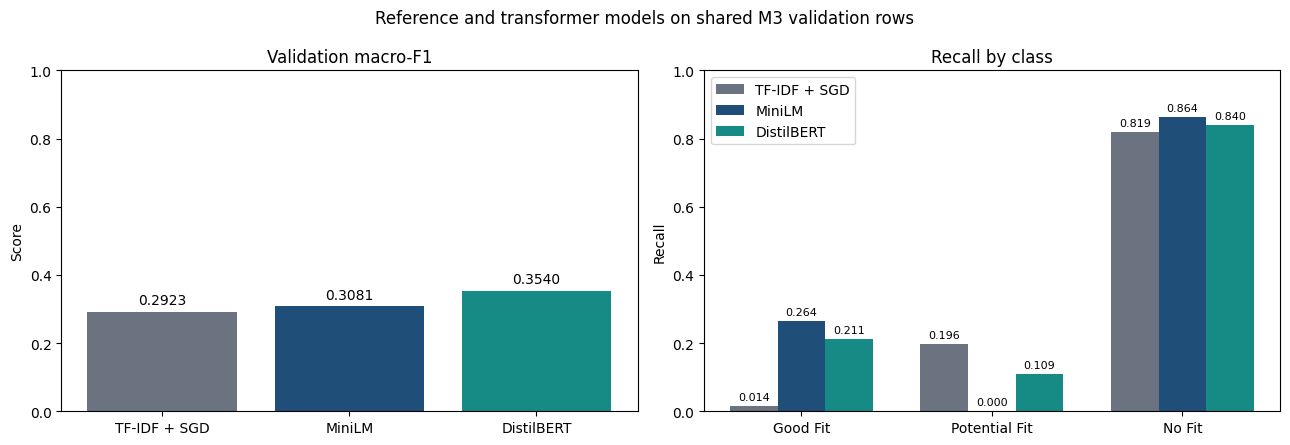

Figure saved to: /content/m4_reference/tfidf_sgd_v1/comparison/reference_model_comparison.png


In [18]:
import matplotlib.pyplot as plt

colors = ["#6B7280", "#1F4E79", "#168A84"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars = axes[0].bar(
    comparison_df["Model"],
    comparison_df["Validation macro-F1"],
    color=colors
)
axes[0].bar_label(bars, fmt="%.4f", padding=3)
axes[0].set_title("Validation macro-F1")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)

positions = np.arange(len(LABELS))
width = 0.25
recall_columns = ["Good Fit recall", "Potential Fit recall", "No Fit recall"]

for index, row in comparison_df.iterrows():
    bars = axes[1].bar(
        positions + (index - 1) * width,
        row[recall_columns].to_numpy(dtype=float),
        width=width,
        label=row["Model"],
        color=colors[index]
    )
    axes[1].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

axes[1].set_xticks(positions, LABELS)
axes[1].set_title("Recall by class")
axes[1].set_ylabel("Recall")
axes[1].set_ylim(0, 1)
axes[1].legend()

fig.suptitle("Reference and transformer models on shared M3 validation rows")
fig.tight_layout()

figure_path = COMPARISON_DIR / "reference_model_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Figure saved to:", figure_path)

In [19]:
scores = comparison_df.set_index("Model")

comparison_notes = f"""# Reference Model Evaluation

## Evaluation setup

The TF-IDF reference and both transformers use the same M3 source rows,
dataset revision, labels, and job-grouped validation split.
No jobs or prepared resume-job pairs overlap between splits.
Some resumes are shared, so this evaluates matching a largely known
candidate pool against unseen jobs.

TF-IDF retains its original baseline cleaning and uses full documents.
The transformers use their recorded preparation and 512-token truncation.
This compares complete approaches; it does not isolate architecture alone.

TF-IDF vocabulary and classifier fitting use training rows only.
The original baseline settings are retained without a validation search.

## Findings

- TF-IDF + SGD validation macro-F1: {scores.loc["TF-IDF + SGD", "Validation macro-F1"]:.4f}.
- MiniLM validation macro-F1: {scores.loc["MiniLM", "Validation macro-F1"]:.4f}.
- DistilBERT validation macro-F1: {scores.loc["DistilBERT", "Validation macro-F1"]:.4f}.
- DistilBERT's absolute gain over the reference: {scores.loc["DistilBERT", "Validation macro-F1"] - reference_f1:.4f}.
- TF-IDF identifies 4 of 280 Good Fit examples and 65 of 331 Potential Fit examples.
- TF-IDF has the highest Potential Fit recall among these runs.
- MiniLM has the highest Good Fit recall.
- DistilBERT leads on macro-F1 and accuracy.

## Limitations and next steps

These are single-seed validation results, not final test results.
All approaches miss many suitable candidates.
Historical M2 test scores use a different split and are not directly comparable.

The saved TF-IDF pipeline reproduces all 1,147 validation predictions.
It expects cleaned pair text, not raw resume and job fields.

Keep this run as the fixed reference for class-weighted training and
section-aware input experiments. Select settings using validation data.
Evaluate the official test set after model selection is fixed.
"""

notes_path = COMPARISON_DIR / "comparison_notes.md"
notes_path.write_text(comparison_notes, encoding="utf-8")

print("Comparison findings saved to:", notes_path)

Comparison findings saved to: /content/m4_reference/tfidf_sgd_v1/comparison/comparison_notes.md


In [20]:
saved_predictions = pd.read_csv(
    REPORT_DIR / "validation_predictions.csv"
)
saved_metrics = json.loads(
    (REPORT_DIR / "validation_metrics.json").read_text()
)
saved_confusion = pd.read_csv(
    REPORT_DIR / "validation_confusion_matrix.csv", index_col=0
)

np.testing.assert_array_equal(
    saved_predictions["source_row_id"],
    validation_df["source_row_id"]
)
np.testing.assert_array_equal(
    saved_predictions["true_label"],
    validation_df["label"]
)
np.testing.assert_array_equal(
    saved_predictions["predicted_label"],
    validation_predictions
)

recomputed_f1 = f1_score(
    saved_predictions["true_label"],
    saved_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)
np.testing.assert_allclose(
    recomputed_f1, saved_metrics["macro_f1"], rtol=1e-12
)
np.testing.assert_array_equal(
    confusion_matrix(
        saved_predictions["true_label"],
        saved_predictions["predicted_label"],
        labels=LABELS
    ),
    saved_confusion.to_numpy()
)
pd.testing.assert_frame_equal(
    pd.read_csv(COMPARISON_DIR / "reference_model_comparison.csv"),
    comparison_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

assert run_summary["official_test_evaluated"] is False
assert json.loads((REPORT_DIR / "reload_check.json").read_text())["passed"]

print("Saved predictions, source rows, metrics, and confusion matrix match.")
print("Comparison CSV and model reload checks passed.")
print("Official test set remains unevaluated.")

Saved predictions, source rows, metrics, and confusion matrix match.
Comparison CSV and model reload checks passed.
Official test set remains unevaluated.


In [21]:
from zipfile import ZIP_DEFLATED

reports_archive = Path("/content/tfidf_sgd_v1_reports.zip")
model_archive = Path("/content/tfidf_sgd_v1_model.zip")

with ZipFile(reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, path.name)

    for path in sorted(COMPARISON_DIR.iterdir()):
        if path.is_file():
            archive.write(path, f"comparison/{path.name}")

with ZipFile(model_archive, "w", ZIP_DEFLATED) as archive:
    archive.write(model_path, model_path.name)
    archive.write(
        REPORT_DIR / "reference_config.json",
        "reference_config.json"
    )

for path in [reports_archive, model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(
            f"{path.name}: {len(archive.namelist())} files, "
            f"{path.stat().st_size / 1024**2:.2f} MB"
        )

files.download(str(reports_archive))
files.download(str(model_archive))

tfidf_sgd_v1_reports.zip: 12 files, 0.12 MB
tfidf_sgd_v1_model.zip: 2 files, 1.35 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Experiment 1: section-aware inputs

Try retaining selected resume and job sections within the same 512-token limit. This is an improvement attempt; its measured score can be lower.


In [23]:
import sys
import subprocess
from importlib.metadata import version

packages = [
    "transformers==5.24.0",
    "huggingface-hub==1.33.0",
    "accelerate==1.15.0",
    "jedi==0.19.2"
]

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", *packages],
    check=True
)
subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    check=True
)

for package in [
    "transformers", "huggingface-hub", "accelerate", "torch"
]:
    print(f"{package}: {version(package)}")

transformers: 5.24.0
huggingface-hub: 1.33.0
accelerate: 1.15.0
torch: 2.14.1+cu130


In [24]:
import random
import numpy as np
import torch
import transformers
import huggingface_hub

from transformers import set_seed

assert transformers.__version__ == "5.24.0"
assert huggingface_hub.__version__ == "1.33.0"
assert torch.cuda.is_available(), "Select a T4 GPU runtime in Colab."

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
set_seed(SEED)

gpu = torch.cuda.get_device_properties(0)
splits_available = (
    "split_frames" in globals()
    and "split_manifest" in globals()
)

print("Transformers loaded:", transformers.__version__)
print("Hub loaded:", huggingface_hub.__version__)
print("GPU:", gpu.name)
print(f"GPU memory: {gpu.total_memory / 1024**3:.1f} GB")
print("Random seed:", SEED)
print("M3 splits available:", splits_available)

if splits_available:
    for name, frame in split_frames.items():
        print(f"{name}: {len(frame):,} rows")
else:
    print("We will restore the saved M3 splits next.")

Transformers loaded: 5.24.0
Hub loaded: 1.33.0
GPU: Tesla T4
GPU memory: 14.6 GB
Random seed: 42
M3 splits available: True
Training: 5,081 rows
Validation: 1,147 rows
Official test: 1,759 rows


In [25]:
from transformers import AutoTokenizer, AutoConfig

SECTION_MODEL_CHECKPOINT = "distilbert/distilbert-base-uncased"
SECTION_MODEL_REVISION = "12040accade4e8a0f71eabdb258fecc2e7e948be"
MAX_LENGTH = 512

section_tokenizer = AutoTokenizer.from_pretrained(
    SECTION_MODEL_CHECKPOINT,
    revision=SECTION_MODEL_REVISION
)
section_model_config = AutoConfig.from_pretrained(
    SECTION_MODEL_CHECKPOINT,
    revision=SECTION_MODEL_REVISION
)

assert section_model_config.model_type == "distilbert"
assert section_model_config.max_position_embeddings == MAX_LENGTH
assert split_manifest["seed"] == SEED
assert LABELS == ["Good Fit", "Potential Fit", "No Fit"]

for frame in split_frames.values():
    assert {"resume_model_text", "job_model_text"}.issubset(frame.columns)

print("Checkpoint:", SECTION_MODEL_CHECKPOINT)
print("Revision:", SECTION_MODEL_REVISION)
print("Input limit:", MAX_LENGTH)
print("Pair special tokens:", section_tokenizer.num_special_tokens_to_add(pair=True))
print("Tokenizer ready. Model weights have not been loaded.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Checkpoint: distilbert/distilbert-base-uncased
Revision: 12040accade4e8a0f71eabdb258fecc2e7e948be
Input limit: 512
Pair special tokens: 3
Tokenizer ready. Model weights have not been loaded.


## Inspect section detection before training

Check heading coverage and extraction rules on training documents. The inspection cells show why the initial rules needed adjustment.


In [26]:
import re

SECTION_PATTERNS = {
    "summary": r"(?:professional |career )?summary|profile|objective|about me",
    "skills": r"(?:(?:technical|core|key|professional) )?skills|core competencies",
    "experience": (
        r"(?:(?:work|professional|relevant|employment) )?experience"
        r"|employment history|work history"
    ),
    "projects": r"(?:(?:personal|academic|selected|relevant) )?projects",
    "education": r"education|academic background|educational qualifications",
    "certifications": r"certifications?|licenses?(?: and certifications?)?",
    "requirements": (
        r"(?:(?:minimum|preferred|required|basic|key) )?"
        r"(?:requirements|qualifications)|what you bring|what we look for"
    ),
    "responsibilities": (
        r"(?:(?:key|job|main) )?(?:responsibilities|duties)"
        r"|what you.ll do|your role"
    ),
    "overview": r"job description|job summary|job overview|about the role",
    "other": r"interests|hobbies|references|languages|benefits|about us"
}

SECTION_REGEX = {
    name: re.compile(
        rf"^(?:{pattern})\s*(?::\s*(?P<content>.*))?$",
        re.IGNORECASE
    )
    for name, pattern in SECTION_PATTERNS.items()
}


def parse_section_heading(line):
    candidate = re.sub(r"^\s*(?:#{1,6}\s*|[-*•]\s+)", "", line)
    candidate = candidate.replace("**", "").replace("__", "").strip()

    for name, pattern in SECTION_REGEX.items():
        match = pattern.fullmatch(candidate)
        if match:
            return name, (match.group("content") or "").strip()

    return None, ""


assert parse_section_heading("## Technical Skills")[0] == "skills"
assert parse_section_heading("**Requirements:** Python")[0] == "requirements"
assert parse_section_heading("Built a Python application")[0] is None

print("Section-heading detection is ready.")

Section-heading detection is ready.


In [27]:
from collections import Counter

coverage_rows = []
heading_counts = {}

for document_type, text_column, group_column in [
    ("Resume", "resume_model_text", "resume_group"),
    ("Job", "job_model_text", "job_group")
]:
    documents = train_df.drop_duplicates(group_column)[text_column]
    counts = Counter()
    recognised_documents = 0

    for text in documents:
        headings = {
            section
            for line in text.splitlines()
            if (section := parse_section_heading(line)[0]) is not None
        }
        recognised_documents += bool(headings)
        counts.update(headings)

    heading_counts[document_type] = counts
    coverage_rows.append({
        "Document type": document_type,
        "Unique documents": len(documents),
        "With recognised headings": recognised_documents,
        "Coverage (%)": round(
            100 * recognised_documents / len(documents), 2
        )
    })

training_section_coverage = pd.DataFrame(coverage_rows)
training_heading_counts = (
    pd.DataFrame(heading_counts)
    .reindex(SECTION_PATTERNS)
    .fillna(0)
    .astype(int)
)
training_heading_counts.index.name = "Section"

display(training_section_coverage)
display(training_heading_counts)
print("Counts show documents containing each section, not heading occurrences.")

,Document type,Unique documents,With recognised headings,Coverage (%)
0,Resume,632,26,4.11
1,Job,229,109,47.60


,Resume,Job
Section,,
summary,0,2
skills,8,5
experience,0,3
projects,0,0
education,13,5
certifications,0,0
requirements,3,58
responsibilities,2,53
overview,0,35


Counts show documents containing each section, not heading occurrences.


In [29]:
heading_probe = re.compile(
    r"\b(?:summary|skills|experience|education|projects|"
    r"employment|qualifications|competencies|certifications?)\b",
    re.IGNORECASE
)

format_rows = []
heading_examples = []

for document_type, text_column, group_column in [
    ("Resume", "resume_model_text", "resume_group"),
    ("Job", "job_model_text", "job_group")
]:
    documents = train_df.drop_duplicates(group_column)[text_column]
    line_counts = documents.map(lambda text: len(text.splitlines()))

    format_rows.append({
        "Document type": document_type,
        "Median lines": float(line_counts.median()),
        "Single-line documents (%)": round(
            100 * line_counts.eq(1).mean(), 2
        )
    })

    examples = set()
    for text in documents:
        for match in heading_probe.finditer(text):
            fragment = text[
                max(0, match.start() - 12):match.end() + 35
            ]
            examples.add(repr(fragment))
            if len(examples) >= 12:
                break
        if len(examples) >= 12:
            break

    heading_examples.extend({
        "Document type": document_type,
        "Heading fragment": fragment
    } for fragment in sorted(examples))

display(pd.DataFrame(format_rows))
display(pd.DataFrame(heading_examples))

,Document type,Median lines,Single-line documents (%)
0,Resume,5.0,0.00
1,Job,6.0,10.92


,Document type,Heading fragment
0,Resume,'NPI and CPI projects Provide technical for CA...
1,Resume,'are for NPI projects including 795FAC XQ (LMT...
2,Resume,'cerning CPI projects Incorporate best busines...
3,Resume,'e and sales experience. Outgoing sales profes...
4,Resume,'iance. this experience provided invaluable in...
5,Resume,"'lights-Soft Skills: Public Speaking, Public R..."
6,Resume,'n Christian Education - Dallas Theological Se...
7,Resume,'onstruction projects. Translates directives o...
8,Resume,'s Conducted projects on various job sites inv...
9,Resume,"'s:Christian Education,Expected in-Dallas Theo..."


In [30]:
SECTION_REGEX = {
    name: re.compile(
        rf"^(?i:{pattern})(?=$|[\s:|]|[A-Z0-9])"
        rf"[\s:|]*(?P<content>.*)$"
    )
    for name, pattern in SECTION_PATTERNS.items()
}


def parse_section_heading(line):
    candidate = re.sub(r"^\s*(?:#{1,6}\s*|[-*•]\s+)", "", line)
    candidate = candidate.replace("**", "").replace("__", "").strip()

    for name, pattern in SECTION_REGEX.items():
        match = pattern.fullmatch(candidate)
        if match:
            return name, match.group("content").strip()

    return None, ""


assert parse_section_heading("SkillsGuest services") == (
    "skills", "Guest services"
)
assert parse_section_heading("ExperienceCompany ABC")[0] == "experience"
assert parse_section_heading("Technical Skills: Python")[0] == "skills"
assert parse_section_heading("Experienced engineer")[0] is None

coverage_rows = []

for document_type, text_column, group_column in [
    ("Resume", "resume_model_text", "resume_group"),
    ("Job", "job_model_text", "job_group")
]:
    documents = train_df.drop_duplicates(group_column)[text_column]
    recognised = sum(
        any(parse_section_heading(line)[0] is not None
            for line in text.splitlines())
        for text in documents
    )
    coverage_rows.append({
        "Document type": document_type,
        "Unique documents": len(documents),
        "With recognised headings": recognised,
        "Coverage (%)": round(100 * recognised / len(documents), 2)
    })

training_section_coverage = pd.DataFrame(coverage_rows)
display(training_section_coverage)

,Document type,Unique documents,With recognised headings,Coverage (%)
0,Resume,632,632,100.00
1,Job,229,156,68.12


In [31]:
def extract_sections(text):
    sections = {"preamble": []}
    current_section = "preamble"

    for line in text.splitlines():
        section_name, inline_content = parse_section_heading(line)

        if section_name is not None:
            current_section = section_name
            sections.setdefault(current_section, [])
            if inline_content:
                sections[current_section].append(inline_content)
        elif line.strip():
            sections.setdefault(current_section, []).append(line.strip())

    return {
        name: "\n".join(parts).strip()
        for name, parts in sections.items()
        if any(part.strip() for part in parts)
    }


example_sections = extract_sections(
    "Candidate profile\nSkillsPython, SQL\nExperienceBuilt data pipelines"
)
assert example_sections["skills"] == "Python, SQL"
assert example_sections["experience"] == "Built data pipelines"
assert extract_sections("Unstructured document") == {
    "preamble": "Unstructured document"
}

section_content_counts = {}

for document_type, text_column, group_column in [
    ("Resume", "resume_model_text", "resume_group"),
    ("Job", "job_model_text", "job_group")
]:
    documents = train_df.drop_duplicates(group_column)[text_column]
    counts = Counter()

    for text in documents:
        counts.update(extract_sections(text).keys())

    section_content_counts[document_type] = counts

training_section_content = (
    pd.DataFrame(section_content_counts)
    .reindex(["preamble", *SECTION_PATTERNS])
    .fillna(0)
    .astype(int)
)
training_section_content.index.name = "Non-empty section"

display(training_section_content)
print("Section extraction checks passed.")

,Resume,Job
Non-empty section,,
preamble,90,207
summary,549,5
skills,495,11
experience,628,22
projects,1,2
education,621,14
certifications,0,0
requirements,46,83
responsibilities,2,77


Section extraction checks passed.


## Fix the section-selection policy

Allocate the token budget before training or validation-based selection. Reassign unused space while preserving the pair input limit.


In [32]:
SECTION_POLICY = {
    "name": "section_aware_v1",
    "max_length": MAX_LENGTH,
    "resume_budget": 304,
    "job_budget": 205,
    "add_section_labels": True,
    "resume_quotas": {
        "skills": 80,
        "experience": 128,
        "summary": 32,
        "education": 24,
        "projects": 24,
        "certifications": 16
    },
    "job_quotas": {
        "requirements": 112,
        "responsibilities": 64,
        "overview": 29
    },
    "resume_priority": [
        "skills", "experience", "summary", "education",
        "projects", "certifications", "preamble",
        "requirements", "responsibilities", "overview", "other"
    ],
    "job_priority": [
        "requirements", "responsibilities", "skills",
        "overview", "experience", "education", "preamble",
        "summary", "projects", "certifications", "other"
    ]
}

PAIR_SPECIAL_TOKENS = section_tokenizer.num_special_tokens_to_add(pair=True)

assert sum(SECTION_POLICY["resume_quotas"].values()) == 304
assert sum(SECTION_POLICY["job_quotas"].values()) == 205
assert 304 + 205 + PAIR_SPECIAL_TOKENS == MAX_LENGTH

for kind in ["resume", "job"]:
    assert set(SECTION_POLICY[f"{kind}_priority"]) == {
        "preamble", *SECTION_PATTERNS
    }

print("Policy:", SECTION_POLICY["name"])
print("Resume budget:", SECTION_POLICY["resume_budget"])
print("Job budget:", SECTION_POLICY["job_budget"])
print("Total limit including special tokens:", MAX_LENGTH)
print("Policy fixed before training or validation-based selection.")

Policy: section_aware_v1
Resume budget: 304
Job budget: 205
Total limit including special tokens: 512
Policy fixed before training or validation-based selection.


In [33]:
def encode_sections(text):
    sections = extract_sections(text)
    encoded = {}

    for name, content in sections.items():
        if SECTION_POLICY["add_section_labels"] and name != "preamble":
            content = f"{name.title()}: {content}"

        encoded[name] = section_tokenizer(
            content,
            add_special_tokens=False,
            truncation=False,
            verbose=False
        )["input_ids"]

    return encoded


def select_section_tokens(encoded_sections, document_type, budget):
    priority = SECTION_POLICY[f"{document_type}_priority"]
    quotas = SECTION_POLICY[f"{document_type}_quotas"]
    selected_counts = {name: 0 for name in encoded_sections}
    remaining = budget

    for name in priority:
        available = len(encoded_sections.get(name, []))
        take = min(available, quotas.get(name, 0), remaining)
        if name in selected_counts:
            selected_counts[name] = take
        remaining -= take

    for name in priority:
        available = len(encoded_sections.get(name, []))
        already_selected = selected_counts.get(name, 0)
        take = min(available - already_selected, remaining)
        if name in selected_counts:
            selected_counts[name] += take
        remaining -= take

    selected_ids = [
        token
        for name in priority
        for token in encoded_sections.get(name, [])[
            :selected_counts.get(name, 0)
        ]
    ]

    assert len(selected_ids) <= budget
    assert len(selected_ids) == sum(selected_counts.values())
    return selected_ids, selected_counts


sample_sections = encode_sections(
    "SkillsPython, SQL\nExperienceBuilt data pipelines"
)
sample_ids, sample_counts = select_section_tokens(
    sample_sections, "resume", SECTION_POLICY["resume_budget"]
)

assert sample_counts["skills"] > 0
assert sample_counts["experience"] > 0
assert len(sample_ids) == sum(map(len, sample_sections.values()))

print("Section encoding and token-selection checks passed.")
print("Short documents retain all extracted section content.")

Section encoding and token-selection checks passed.
Short documents retain all extracted section content.


In [34]:
def build_section_pair(resume_sections, job_sections):
    content_budget = MAX_LENGTH - PAIR_SPECIAL_TOKENS
    resume_available = sum(map(len, resume_sections.values()))
    job_available = sum(map(len, job_sections.values()))

    assert resume_available > 0 and job_available > 0

    resume_budget = min(
        SECTION_POLICY["resume_budget"], resume_available
    )
    job_budget = min(content_budget - resume_budget, job_available)
    resume_budget = min(content_budget - job_budget, resume_available)

    resume_ids, resume_counts = select_section_tokens(
        resume_sections, "resume", resume_budget
    )
    job_ids, job_counts = select_section_tokens(
        job_sections, "job", job_budget
    )

    input_ids = (
        [section_tokenizer.cls_token_id]
        + resume_ids
        + [section_tokenizer.sep_token_id]
        + job_ids
        + [section_tokenizer.sep_token_id]
    )

    assert len(input_ids) <= MAX_LENGTH
    assert len(input_ids) == len(resume_ids) + len(job_ids) + 3

    features = {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids)
    }
    allocation = {
        "resume": resume_counts,
        "job": job_counts
    }
    return features, allocation


probe_resume = section_tokenizer(
    "Python", add_special_tokens=False
)["input_ids"]
probe_job = section_tokenizer(
    "SQL", add_special_tokens=False
)["input_ids"]

assert section_tokenizer("Python", "SQL")["input_ids"] == (
    [section_tokenizer.cls_token_id] + probe_resume
    + [section_tokenizer.sep_token_id] + probe_job
    + [section_tokenizer.sep_token_id]
)

sample_features, sample_allocation = build_section_pair(
    sample_sections,
    encode_sections("RequirementsPython and SQL")
)

print("Pair construction matches the tokenizer's special-token format.")
print("Sample input length:", len(sample_features["input_ids"]))
print("Unused document space is reassigned within the 512-token limit.")

Pair construction matches the tokenizer's special-token format.
Sample input length: 19
Unused document space is reassigned within the 512-token limit.


In [35]:
from tqdm.auto import tqdm

SECTION_SPLITS = ["Training", "Validation"]
section_cache = {}

for document_type, text_column in [
    ("resume", "resume_model_text"),
    ("job", "job_model_text")
]:
    unique_texts = (
        pd.concat(
            [split_frames[name][text_column] for name in SECTION_SPLITS],
            ignore_index=True
        )
        .drop_duplicates()
        .tolist()
    )

    section_cache[document_type] = {
        text: encode_sections(text)
        for text in tqdm(
            unique_texts,
            desc=f"Encoding unique {document_type} documents"
        )
    }

    assert all(
        sum(map(len, sections.values())) > 0
        for sections in section_cache[document_type].values()
    )

    fallback_count = sum(
        set(sections) == {"preamble"}
        for sections in section_cache[document_type].values()
    )

    print(
        f"{document_type.title()}: {len(unique_texts):,} unique texts; "
        f"{fallback_count:,} use preamble-only fallback"
    )

print("Section cache ready. Official test documents were not processed.")

Encoding unique resume documents:   0%|          | 0/642 [00:00<?, ?it/s]

Resume: 642 unique texts; 0 use preamble-only fallback


Encoding unique job documents:   0%|          | 0/280 [00:00<?, ?it/s]

Job: 280 unique texts; 93 use preamble-only fallback
Section cache ready. Official test documents were not processed.


In [38]:
from datasets import Dataset, DatasetDict

section_datasets = DatasetDict()
allocation_rows = []

for split_name in SECTION_SPLITS:
    frame = split_frames[split_name]
    records = []

    for row in tqdm(
        frame.itertuples(index=False),
        total=len(frame),
        desc=f"Building {split_name}"
    ):
        features, allocation = build_section_pair(
            section_cache["resume"][row.resume_model_text],
            section_cache["job"][row.job_model_text]
        )
        features["labels"] = int(row.labels)
        records.append(features)

        audit = {
            "Split": split_name,
            "source_row_id": int(row.source_row_id),
            "input_tokens": len(features["input_ids"]),
            "resume_tokens": sum(allocation["resume"].values()),
            "job_tokens": sum(allocation["job"].values())
        }
        for document_type in ["resume", "job"]:
            for section_name in ["preamble", *SECTION_PATTERNS]:
                audit[f"{document_type}_{section_name}_tokens"] = (
                    allocation[document_type].get(section_name, 0)
                )
        allocation_rows.append(audit)

    section_datasets[split_name] = Dataset.from_list(records)

    np.testing.assert_array_equal(
        section_datasets[split_name]["labels"],
        frame["labels"].to_numpy()
    )
    assert len(section_datasets[split_name]) == len(frame)

section_allocation_report = pd.DataFrame(allocation_rows)

assert section_allocation_report["input_tokens"].le(MAX_LENGTH).all()
assert (
    section_allocation_report["resume_tokens"]
    + section_allocation_report["job_tokens"]
    + PAIR_SPECIAL_TOKENS
).equals(section_allocation_report["input_tokens"])

for name, data in section_datasets.items():
    print(name, len(data), data.column_names)

print("Section-aware datasets and allocation checks passed.")

Building Training:   0%|          | 0/5081 [00:00<?, ?it/s]

Building Validation:   0%|          | 0/1147 [00:00<?, ?it/s]

Training 5081 ['input_ids', 'attention_mask', 'labels']
Validation 1147 ['input_ids', 'attention_mask', 'labels']
Section-aware datasets and allocation checks passed.


In [40]:
section_length_summary = (
    section_allocation_report
    .groupby("Split", sort=False)
    .agg(
        Rows=("input_tokens", "size"),
        Minimum_tokens=("input_tokens", "min"),
        Maximum_tokens=("input_tokens", "max"),
        Mean_resume_tokens=("resume_tokens", "mean"),
        Mean_job_tokens=("job_tokens", "mean")
    )
)

section_token_columns = [
    f"{kind}_{section_name}_tokens"
    for kind, section_names in [
        ("resume", ["skills", "experience", "summary", "education", "projects"]),
        ("job", ["requirements", "responsibilities", "overview", "preamble"])
    ]
    for section_name in section_names
]

section_token_summary = (
    section_allocation_report
    .groupby("Split", sort=False)[section_token_columns]
    .mean()
    .T
)
section_token_summary.index.name = "Section token allocation"

assert section_allocation_report["resume_tokens"].gt(0).all()
assert section_allocation_report["job_tokens"].gt(0).all()

display(section_length_summary.round(2))
display(section_token_summary.round(2))
print("Token counts include section labels.")

,Rows,Minimum_tokens,Maximum_tokens,Mean_resume_tokens,Mean_job_tokens
Split,,,,,
Training,5081,331,512,316.40,192.44
Validation,1147,437,512,327.51,181.30


Split,Training,Validation
Section token allocation,,
resume_skills_tokens,77.72,76.47
resume_experience_tokens,185.40,197.46
resume_summary_tokens,28.73,28.88
resume_education_tokens,24.38,24.23
resume_projects_tokens,0.02,0.02
job_requirements_tokens,40.87,31.19
job_responsibilities_tokens,29.45,20.31
job_overview_tokens,27.54,14.02
job_preamble_tokens,83.06,101.73


Token counts include section labels.


In [41]:
from transformers import DataCollatorWithPadding

section_collator = DataCollatorWithPadding(
    tokenizer=section_tokenizer,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

training_lengths = np.array([
    len(ids) for ids in section_datasets["Training"]["input_ids"]
])
sorted_indices = np.argsort(training_lengths)
batch_indices = [
    int(index)
    for index in np.concatenate([sorted_indices[:4], sorted_indices[-4:]])
]

section_check_batch = section_collator([
    section_datasets["Training"][index]
    for index in batch_indices
])

assert set(section_check_batch) == {
    "input_ids", "attention_mask", "labels"
}
assert section_check_batch["labels"].dtype == torch.int64
assert section_check_batch["input_ids"].shape == (8, MAX_LENGTH)

np.testing.assert_array_equal(
    section_check_batch["attention_mask"].sum(dim=1).numpy(),
    training_lengths[batch_indices]
)

print("Batch shapes:", {
    key: tuple(value.shape)
    for key, value in section_check_batch.items()
})
print(
    "Padding tokens:",
    int(section_check_batch["attention_mask"].eq(0).sum())
)
print("Label dtype:", section_check_batch["labels"].dtype)
print("Dynamic-padding checks passed.")

Batch shapes: {'input_ids': (8, 512), 'attention_mask': (8, 512), 'labels': (8,)}
Padding tokens: 485
Label dtype: torch.int64
Dynamic-padding checks passed.


## Train the section-aware candidate

Load the original DistilBERT settings for a matched experiment. Change the input policy and keep the unweighted training loss.


In [42]:
import io
import json
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

baseline_archive_path = Path("/content/distilbert_v1_reports.zip")

if baseline_archive_path.exists():
    baseline_archive_bytes = baseline_archive_path.read_bytes()
    print("Reusing:", baseline_archive_path.name)
else:
    baseline_upload = files.upload()
    assert len(baseline_upload) == 1, "Upload distilbert_v1_reports.zip."
    baseline_archive_bytes = next(iter(baseline_upload.values()))

with ZipFile(io.BytesIO(baseline_archive_bytes)) as archive:
    original_distilbert_summary = json.loads(
        archive.read("run_summary.json")
    )
    original_distilbert_metrics = json.loads(
        archive.read("validation_metrics.json")
    )
    original_distilbert_arguments = json.loads(
        archive.read("training_arguments.json")
    )
    original_tokenization_config = json.loads(
        archive.read("tokenization_config.json")
    )

assert original_distilbert_summary["run_id"] == "distilbert_v1"
assert original_distilbert_summary["model_revision"] == SECTION_MODEL_REVISION
assert original_distilbert_summary["dataset_revision"] == (
    split_manifest["dataset_revision"]
)
assert original_distilbert_summary["seed"] == SEED
assert original_distilbert_summary["split_rows"] == {
    name: len(frame) for name, frame in split_frames.items()
}
assert original_tokenization_config["label2id"] == LABEL2ID
assert original_distilbert_summary["official_test_evaluated"] is False

print(
    "Original validation macro-F1:",
    round(original_distilbert_metrics["validation_macro_f1"], 4)
)
print("Original training settings loaded for the matched experiment.")

Reusing: distilbert_v1_reports.zip
Original validation macro-F1: 0.354
Original training settings loaded for the matched experiment.


In [43]:
from transformers import AutoModelForSequenceClassification

set_seed(SEED)
ID2LABEL = {index: label for label, index in LABEL2ID.items()}

section_model = AutoModelForSequenceClassification.from_pretrained(
    SECTION_MODEL_CHECKPOINT,
    revision=SECTION_MODEL_REVISION,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to("cuda")

assert section_model.config.label2id == LABEL2ID
assert all(parameter.requires_grad for parameter in section_model.parameters())

section_forward_batch = {
    key: value.to("cuda")
    for key, value in section_check_batch.items()
}

section_model.eval()
with torch.no_grad():
    section_diagnostic_output = section_model(**section_forward_batch)

assert section_diagnostic_output.logits.shape == (8, len(LABELS))
assert torch.isfinite(section_diagnostic_output.logits).all()
assert torch.isfinite(section_diagnostic_output.loss)

print("Checkpoint:", SECTION_MODEL_CHECKPOINT)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in section_model.parameters()):,}"
)
print("Logits shape:", tuple(section_diagnostic_output.logits.shape))
print(f"Diagnostic loss: {section_diagnostic_output.loss.item():.4f}")
print("Forward-pass checks passed. No weights were updated.")

del section_diagnostic_output, section_forward_batch

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: distilbert/distilbert-base-uncased
Trainable parameters: 66,955,779
Logits shape: (8, 3)
Diagnostic loss: 1.0835
Forward-pass checks passed. No weights were updated.


In [44]:
import math
from transformers import TrainingArguments

SECTION_OUTPUT_DIR = "/content/m4_training/distilbert_section_v1"

section_argument_values = original_distilbert_arguments.copy()
section_argument_values["output_dir"] = SECTION_OUTPUT_DIR

section_training_args = TrainingArguments(**section_argument_values)
resolved_section_arguments = section_training_args.to_dict()

for key, original_value in original_distilbert_arguments.items():
    if key != "output_dir":
        assert resolved_section_arguments[key] == original_value, key

effective_batch_size = (
    section_training_args.per_device_train_batch_size
    * section_training_args.gradient_accumulation_steps
)
updates_per_epoch = math.ceil(
    math.ceil(
        len(section_datasets["Training"])
        / section_training_args.per_device_train_batch_size
    )
    / section_training_args.gradient_accumulation_steps
)

print("Output directory:", SECTION_OUTPUT_DIR)
print("Maximum epochs:", section_training_args.num_train_epochs)
print("Learning rate:", section_training_args.learning_rate)
print("Effective batch size:", effective_batch_size)
print("Optimizer updates per epoch:", updates_per_epoch)
print("Warmup updates:", section_training_args.warmup_steps)
print("Checkpoint metric:", section_training_args.metric_for_best_model)
print("All saved training arguments match except the output directory.")

Output directory: /content/m4_training/distilbert_section_v1
Maximum epochs: 3
Learning rate: 2e-05
Effective batch size: 16
Optimizer updates per epoch: 318
Warmup updates: 96
Checkpoint metric: macro_f1
All saved training arguments match except the output directory.


In [45]:
from sklearn.metrics import accuracy_score, f1_score, recall_score
from transformers import Trainer, EarlyStoppingCallback


def section_compute_metrics(evaluation):
    predictions = np.argmax(evaluation.predictions, axis=-1)
    true_labels = evaluation.label_ids
    label_ids = list(range(len(LABELS)))

    recalls = recall_score(
        true_labels, predictions,
        labels=label_ids, average=None, zero_division=0
    )

    return {
        "accuracy": accuracy_score(true_labels, predictions),
        "macro_f1": f1_score(
            true_labels, predictions,
            labels=label_ids, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            true_labels, predictions,
            labels=label_ids, average="weighted", zero_division=0
        ),
        "recall_good_fit": recalls[0],
        "recall_potential_fit": recalls[1],
        "recall_no_fit": recalls[2]
    }


set_seed(SEED)

section_trainer = Trainer(
    model=section_model,
    args=section_training_args,
    train_dataset=section_datasets["Training"],
    eval_dataset=section_datasets["Validation"],
    processing_class=section_tokenizer,
    data_collator=section_collator,
    compute_metrics=section_compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

assert section_trainer.state.global_step == 0
assert section_model.config.problem_type in {
    None, "single_label_classification"
}

print("Trainer ready.")
print("Loss: unweighted cross-entropy")
print("Early-stopping patience: 1")
print("Official test set is not passed to the trainer.")
print("Training has not started.")

Trainer ready.
Loss: unweighted cross-entropy
Early-stopping patience: 1
Official test set is not passed to the trainer.
Training has not started.


In [46]:
import time

assert section_trainer.state.global_step == 0, (
    "Training already started. Reinitialise the model and trainer "
    "before starting an independent run."
)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

section_training_started = time.perf_counter()
section_training_result = section_trainer.train()
torch.cuda.synchronize()

section_training_seconds = time.perf_counter() - section_training_started
section_peak_gpu_gb = torch.cuda.max_memory_allocated() / 1024**3

print(f"Training wall time: {section_training_seconds / 60:.2f} minutes")
print(f"Peak GPU allocation: {section_peak_gpu_gb:.2f} GB")
print("Optimizer updates:", section_trainer.state.global_step)
print(
    "Best validation macro-F1:",
    round(float(section_trainer.state.best_metric), 4)
)
print("Best checkpoint:", section_trainer.state.best_model_checkpoint)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Recall Good Fit,Recall Potential Fit,Recall No Fit
1,1.728621,1.066415,0.449869,0.295054,0.357127,0.175000,0.030211,0.852612
2,1.492845,1.236508,0.478640,0.325797,0.392467,0.050000,0.181269,0.886194
3,1.455226,1.397961,0.479512,0.317372,0.389125,0.035714,0.172205,0.901119


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training wall time: 4.60 minutes
Peak GPU allocation: 1.95 GB
Optimizer updates: 954
Best validation macro-F1: 0.3258
Best checkpoint: /content/m4_training/distilbert_section_v1/checkpoint-636


## Evaluate the section-aware experiment

Compare macro-F1 and class recall with the original policy. The original policy remains stronger for this run.


In [47]:
from sklearn.metrics import classification_report, confusion_matrix

section_validation_output = section_trainer.predict(
    section_datasets["Validation"],
    metric_key_prefix="validation"
)

section_validation_predictions = np.argmax(
    section_validation_output.predictions, axis=-1
)
section_validation_labels = section_validation_output.label_ids

np.testing.assert_array_equal(
    section_validation_labels,
    validation_df["labels"].to_numpy()
)
np.testing.assert_allclose(
    section_validation_output.metrics["validation_macro_f1"],
    section_trainer.state.best_metric,
    rtol=1e-6
)

section_class_report = pd.DataFrame(
    classification_report(
        section_validation_labels,
        section_validation_predictions,
        labels=list(range(len(LABELS))),
        target_names=LABELS,
        output_dict=True,
        zero_division=0
    )
).T.loc[LABELS]

section_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        section_validation_labels,
        section_validation_predictions,
        labels=list(range(len(LABELS)))
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

display(section_class_report.round(4))
display(section_confusion_matrix)
print(
    "Selected-checkpoint validation macro-F1:",
    round(section_validation_output.metrics["validation_macro_f1"], 4)
)

,precision,recall,f1-score,support
Good Fit,0.2456,0.0500,0.0831,280.0
Potential Fit,0.4348,0.1813,0.2559,331.0
No Fit,0.4989,0.8862,0.6384,536.0


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,14,32,234
Potential Fit,28,60,243
No Fit,15,46,475


Selected-checkpoint validation macro-F1: 0.3258


In [48]:
SECTION_RUN_DIR = Path(SECTION_OUTPUT_DIR)
SECTION_MODEL_DIR = SECTION_RUN_DIR / "best_model"
SECTION_REPORT_DIR = SECTION_RUN_DIR / "reports"
SECTION_REPORT_DIR.mkdir(parents=True, exist_ok=True)

section_trainer.save_model(str(SECTION_MODEL_DIR))
section_tokenizer.save_pretrained(str(SECTION_MODEL_DIR))

pd.DataFrame(section_trainer.state.log_history).to_csv(
    SECTION_REPORT_DIR / "training_history.csv", index=False
)
section_class_report.to_csv(
    SECTION_REPORT_DIR / "validation_class_report.csv",
    index_label="label"
)
section_confusion_matrix.to_csv(
    SECTION_REPORT_DIR / "validation_confusion_matrix.csv"
)
(SECTION_REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(section_validation_output.metrics, indent=2),
    encoding="utf-8"
)

section_prediction_report = pd.DataFrame({
    "source_row_id": validation_df["source_row_id"].to_numpy(),
    "true_label": [ID2LABEL[int(i)] for i in section_validation_labels],
    "predicted_label": [
        ID2LABEL[int(i)] for i in section_validation_predictions
    ]
})
section_prediction_report["correct"] = (
    section_prediction_report["true_label"]
    == section_prediction_report["predicted_label"]
)
section_prediction_report.to_csv(
    SECTION_REPORT_DIR / "validation_predictions.csv", index=False
)

print("Selected model saved to:", SECTION_MODEL_DIR)
for path in sorted(SECTION_REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Selected model saved to: /content/m4_training/distilbert_section_v1/best_model
training_history.csv: 4,492 bytes
validation_class_report.csv: 247 bytes
validation_confusion_matrix.csv: 101 bytes
validation_metrics.json: 446 bytes
validation_predictions.csv: 31,936 bytes


In [49]:
section_input_config = {
    "run_id": "distilbert_section_v1",
    "dataset": split_manifest["dataset"],
    "dataset_revision": split_manifest["dataset_revision"],
    "split_manifest_sha256": hashlib.sha256(
        json.dumps(
            split_manifest, sort_keys=True, separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest(),
    "model": SECTION_MODEL_CHECKPOINT,
    "model_revision": SECTION_MODEL_REVISION,
    "seed": SEED,
    "label2id": LABEL2ID,
    "policy": SECTION_POLICY,
    "heading_regex": {
        name: pattern.pattern
        for name, pattern in SECTION_REGEX.items()
    },
    "text_preparation": "Shared M3 prepare_text function",
    "heading_cleanup": "Remove leading Markdown heading/bullet and bold markers",
    "section_truncation": "Keep the prefix within each section allowance",
    "fallback": "Unrecognised lines remain in the current section or preamble",
    "pair_order": ["resume", "job"],
    "padding": "Dynamic, rounded to a multiple of 8",
    "python_version": sys.version.split()[0],
    "package_versions": {
        package: version(package)
        for package in [
            "transformers", "huggingface-hub", "tokenizers",
            "accelerate", "torch", "numpy", "pandas",
            "datasets", "scikit-learn"
        ]
    }
}

for filename, content in [
    ("section_input_config.json", section_input_config),
    ("training_arguments.json", section_training_args.to_dict())
]:
    (SECTION_REPORT_DIR / filename).write_text(
        json.dumps(content, indent=2), encoding="utf-8"
    )

print("Section-input configuration and training arguments saved.")

Section-input configuration and training arguments saved.


In [50]:
section_prediction_counts = np.bincount(
    section_validation_predictions, minlength=len(LABELS)
)

section_run_summary = {
    "run_id": "distilbert_section_v1",
    "model": SECTION_MODEL_CHECKPOINT,
    "model_revision": SECTION_MODEL_REVISION,
    "dataset_revision": split_manifest["dataset_revision"],
    "seed": SEED,
    "loss": "unweighted cross-entropy",
    "input_policy": SECTION_POLICY["name"],
    "split_rows": {
        name: len(frame) for name, frame in split_frames.items()
    },
    "epochs_run": float(section_trainer.state.epoch),
    "best_checkpoint": Path(
        section_trainer.state.best_model_checkpoint
    ).name,
    "best_validation_macro_f1": float(section_trainer.state.best_metric),
    "optimizer_updates": section_trainer.state.global_step,
    "training_wall_seconds": section_training_seconds,
    "peak_gpu_allocated_gb": section_peak_gpu_gb,
    "validation_prediction_counts": {
        label: int(section_prediction_counts[index])
        for index, label in enumerate(LABELS)
    },
    "official_test_processed_with_section_policy": False,
    "official_test_evaluated": False
}

(SECTION_REPORT_DIR / "run_summary.json").write_text(
    json.dumps(section_run_summary, indent=2), encoding="utf-8"
)

audit_reports = {
    "training_section_coverage.csv": (training_section_coverage, False),
    "training_section_content.csv": (training_section_content, True),
    "section_allocation.csv": (section_allocation_report, False),
    "section_length_summary.csv": (section_length_summary, True),
    "section_token_summary.csv": (section_token_summary, True)
}

for filename, (report, include_index) in audit_reports.items():
    report.to_csv(
        SECTION_REPORT_DIR / filename, index=include_index
    )

print(json.dumps(section_run_summary, indent=2))
print("Five section-audit reports saved.")

{
  "run_id": "distilbert_section_v1",
  "model": "distilbert/distilbert-base-uncased",
  "model_revision": "12040accade4e8a0f71eabdb258fecc2e7e948be",
  "dataset_revision": "08978e21714984bb417547d2c0f9b477f5298163",
  "seed": 42,
  "loss": "unweighted cross-entropy",
  "input_policy": "section_aware_v1",
  "split_rows": {
    "Training": 5081,
    "Validation": 1147,
    "Official test": 1759
  },
  "epochs_run": 3.0,
  "best_checkpoint": "checkpoint-636",
  "best_validation_macro_f1": 0.32579681769104857,
  "optimizer_updates": 954,
  "training_wall_seconds": 275.7695493450001,
  "peak_gpu_allocated_gb": 1.9528608322143555,
  "validation_prediction_counts": {
    "Good Fit": 57,
    "Potential Fit": 138,
    "No Fit": 952
  },
  "official_test_processed_with_section_policy": false,
  "official_test_evaluated": false
}
Five section-audit reports saved.


In [51]:
section_reloaded_tokenizer = AutoTokenizer.from_pretrained(
    str(SECTION_MODEL_DIR), local_files_only=True
)
section_reloaded_model = AutoModelForSequenceClassification.from_pretrained(
    str(SECTION_MODEL_DIR), local_files_only=True
).to("cuda")

original_state = section_trainer.model.state_dict()
reloaded_state = section_reloaded_model.state_dict()

assert original_state.keys() == reloaded_state.keys()

for name in original_state:
    assert torch.equal(
        original_state[name].detach().cpu(),
        reloaded_state[name].detach().cpu()
    ), name

assert section_reloaded_tokenizer.get_vocab() == (
    section_tokenizer.get_vocab()
)
assert section_reloaded_tokenizer.special_tokens_map == (
    section_tokenizer.special_tokens_map
)
assert section_reloaded_model.config.label2id == LABEL2ID
assert section_reloaded_model.config.id2label == ID2LABEL
assert json.loads(
    (SECTION_REPORT_DIR / "section_input_config.json").read_text()
) == section_input_config

print("Tensors checked:", len(original_state))
print("All saved weights and persistent buffers match exactly.")
print("Tokenizer, labels, and section-input configuration also match.")

del original_state, reloaded_state

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tensors checked: 104
All saved weights and persistent buffers match exactly.
Tokenizer, labels, and section-input configuration also match.


In [52]:
section_reload_batch = {
    key: value.to("cuda")
    for key, value in section_collator([
        section_datasets["Validation"][index]
        for index in range(2)
    ]).items()
    if key != "labels"
}

section_trainer.model.eval()
section_reloaded_model.eval()

with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
    original_logits = section_trainer.model(**section_reload_batch).logits.float()
    reloaded_logits = section_reloaded_model(**section_reload_batch).logits.float()

torch.testing.assert_close(
    original_logits, reloaded_logits, rtol=1e-4, atol=1e-5
)
assert torch.equal(
    original_logits.argmax(dim=-1),
    reloaded_logits.argmax(dim=-1)
)

section_reload_check = {
    "weights_match_exactly": True,
    "tokenizer_and_labels_match": True,
    "section_input_config_matches": True,
    "comparison_precision": "FP16 autocast",
    "validation_examples_checked": 2,
    "maximum_logit_difference": float(
        (original_logits - reloaded_logits).abs().max().item()
    ),
    "passed": True
}

(SECTION_REPORT_DIR / "reload_check.json").write_text(
    json.dumps(section_reload_check, indent=2), encoding="utf-8"
)

print(json.dumps(section_reload_check, indent=2))

del section_reloaded_model, section_reload_batch
del original_logits, reloaded_logits
torch.cuda.empty_cache()

{
  "weights_match_exactly": true,
  "tokenizer_and_labels_match": true,
  "section_input_config_matches": true,
  "comparison_precision": "FP16 autocast",
  "validation_examples_checked": 2,
  "maximum_logit_difference": 0.0,
  "passed": true
}


In [53]:
section_comparison_rows = []

for policy_name, metrics in [
    ("Original longest_first", original_distilbert_metrics),
    ("Section-aware v1", section_validation_output.metrics)
]:
    section_comparison_rows.append({
        "Input policy": policy_name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"]
    })

section_comparison_df = pd.DataFrame(section_comparison_rows)
SECTION_COMPARISON_DIR = SECTION_RUN_DIR / "comparison"
SECTION_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

section_comparison_df.to_csv(
    SECTION_COMPARISON_DIR / "input_policy_comparison.csv",
    index=False
)

section_macro_f1_change = (
    section_validation_output.metrics["validation_macro_f1"]
    - original_distilbert_metrics["validation_macro_f1"]
)

display(section_comparison_df.round(4))
print(f"Macro-F1 change: {section_macro_f1_change:+.4f}")
print("Original DistilBERT remains the stronger candidate by macro-F1.")
print("Official test set remains unevaluated.")

,Input policy,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,Original longest_first,0.3540,0.4752,0.2107,0.1088,0.8396
1,Section-aware v1,0.3258,0.4786,0.0500,0.1813,0.8862


Macro-F1 change: -0.0282
Original DistilBERT remains the stronger candidate by macro-F1.
Official test set remains unevaluated.


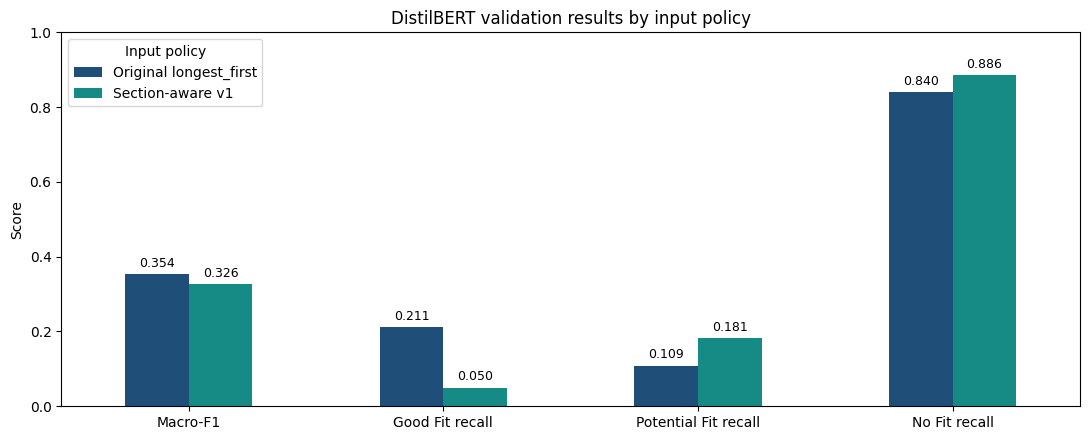

Figure saved to: /content/m4_training/distilbert_section_v1/comparison/input_policy_comparison.png


In [54]:
import matplotlib.pyplot as plt

plot_columns = [
    "Validation macro-F1",
    "Good Fit recall",
    "Potential Fit recall",
    "No Fit recall"
]

plot_data = section_comparison_df.set_index("Input policy")[plot_columns].T
plot_data.index = [
    "Macro-F1", "Good Fit recall", "Potential Fit recall", "No Fit recall"
]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 4.5),
    color=["#1F4E79", "#168A84"],
    rot=0
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("DistilBERT validation results by input policy")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.legend(title="Input policy")

figure = ax.get_figure()
figure.tight_layout()
figure_path = SECTION_COMPARISON_DIR / "input_policy_comparison.png"
figure.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(figure)

print("Figure saved to:", figure_path)

In [55]:
section_comparison_notes = f"""# Section-Aware Input Evaluation

## Experiment setup

Both runs use the same DistilBERT checkpoint revision, M3 source rows,
labels, seed, unweighted loss, and saved training arguments.
Only the output directory differs in the training arguments.
Both runs select epoch 2 using validation macro-F1.

The new input policy detects sections, adds section labels, reorders content,
and allocates 304 resume tokens and 205 job tokens before reassigning unused
space. Three special tokens complete the 512-token limit.

## Results

- Original validation macro-F1: {original_distilbert_metrics["validation_macro_f1"]:.4f}.
- Section-aware validation macro-F1: {section_validation_output.metrics["validation_macro_f1"]:.4f}.
- Absolute macro-F1 change: {section_macro_f1_change:+.4f}.
- Good Fit recall falls from 0.2107 to 0.0500.
- Potential Fit recall rises from 0.1088 to 0.1813.
- No Fit recall rises from 0.8396 to 0.8862.
- Section-aware predictions include 57 Good Fit, 138 Potential Fit, and 952 No Fit.
- The model correctly identifies 14 of 280 Good Fit examples.

## Decision

Keep the original DistilBERT input policy as the stronger candidate.
The small accuracy increase does not offset lower macro-F1 and Good Fit recall.
Record this as an unsuccessful improvement iteration.

## Limitations

Heading detection was adjusted using training documents only.
Recognising headings does not establish correct section boundaries.
English heading rules may miss unusual layouts or interpret content as headings.

The policy changes section selection, ordering, labels, and token allocation
together. This experiment does not isolate their individual effects.
Reordering or discarding context could affect results, but no specific cause
has been established.

These are single-seed validation results. Section labels count toward the token
budget, so allocation counts are not measurements of original-content retention.
The official test set was neither processed with this policy nor evaluated.

Keep class-weighted training separate so its effect can be assessed against
the original input policy.
"""

notes_path = SECTION_COMPARISON_DIR / "comparison_notes.md"
notes_path.write_text(section_comparison_notes, encoding="utf-8")

print("Findings and decision saved to:", notes_path)

Findings and decision saved to: /content/m4_training/distilbert_section_v1/comparison/comparison_notes.md


In [56]:
saved_section_predictions = pd.read_csv(
    SECTION_REPORT_DIR / "validation_predictions.csv"
)
saved_section_metrics = json.loads(
    (SECTION_REPORT_DIR / "validation_metrics.json").read_text()
)
saved_section_confusion = pd.read_csv(
    SECTION_REPORT_DIR / "validation_confusion_matrix.csv",
    index_col=0
)

np.testing.assert_array_equal(
    saved_section_predictions["source_row_id"],
    validation_df["source_row_id"].to_numpy()
)
np.testing.assert_array_equal(
    saved_section_predictions["true_label"],
    validation_df["label"].to_numpy()
)

recomputed_section_f1 = f1_score(
    saved_section_predictions["true_label"],
    saved_section_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)
np.testing.assert_allclose(
    recomputed_section_f1,
    saved_section_metrics["validation_macro_f1"],
    rtol=1e-12
)
np.testing.assert_array_equal(
    confusion_matrix(
        saved_section_predictions["true_label"],
        saved_section_predictions["predicted_label"],
        labels=LABELS
    ),
    saved_section_confusion.to_numpy()
)
pd.testing.assert_frame_equal(
    pd.read_csv(SECTION_COMPARISON_DIR / "input_policy_comparison.csv"),
    section_comparison_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

assert json.loads(
    (SECTION_REPORT_DIR / "reload_check.json").read_text()
)["passed"]
assert section_run_summary["official_test_evaluated"] is False
assert section_run_summary["best_checkpoint"] == "checkpoint-636"

print("Saved source rows, metrics, and confusion matrix match.")
print("Comparison CSV and model reload checks passed.")
print("Official test set remains unevaluated.")

Saved source rows, metrics, and confusion matrix match.
Comparison CSV and model reload checks passed.
Official test set remains unevaluated.


In [57]:
from zipfile import ZIP_DEFLATED

section_reports_archive = Path(
    "/content/distilbert_section_v1_reports.zip"
)
section_model_archive = Path(
    "/content/distilbert_section_v1_model.zip"
)

with ZipFile(section_reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(SECTION_REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, path.name)

    for path in sorted(SECTION_COMPARISON_DIR.iterdir()):
        if path.is_file():
            archive.write(path, f"comparison/{path.name}")

model_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json"
]

with ZipFile(section_model_archive, "w", ZIP_DEFLATED) as archive:
    for filename in model_files:
        path = SECTION_MODEL_DIR / filename
        assert path.exists(), filename
        archive.write(path, filename)

    archive.write(
        SECTION_REPORT_DIR / "section_input_config.json",
        "section_input_config.json"
    )

for path in [section_reports_archive, section_model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(
            f"{path.name}: {len(archive.namelist())} files, "
            f"{path.stat().st_size / 1024**2:.2f} MB"
        )

files.download(str(section_reports_archive))
files.download(str(section_model_archive))

distilbert_section_v1_reports.zip: 17 files, 0.15 MB
distilbert_section_v1_model.zip: 5 files, 235.75 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Experiment 2: class-weighted training

Compute weight = training rows / (number of classes * class count). Validation and test labels do not determine these weights.


In [58]:
WEIGHTED_OUTPUT_DIR = "/content/m4_training/distilbert_weighted_v1"

training_label_ids = train_df["labels"].to_numpy()
training_class_counts = np.bincount(
    training_label_ids, minlength=len(LABELS)
)

assert len(training_label_ids) == 5081
assert (training_class_counts > 0).all()
assert LABELS == ["Good Fit", "Potential Fit", "No Fit"]

class_weight_values = (
    len(training_label_ids)
    / (len(LABELS) * training_class_counts)
)
CLASS_WEIGHTS = torch.tensor(
    class_weight_values, dtype=torch.float32
)

class_weight_report = pd.DataFrame({
    "Label": LABELS,
    "Training examples": training_class_counts,
    "Class weight": class_weight_values
})

display(class_weight_report.round(4))
print("Formula: training rows / (number of classes × class count)")
print("Validation and test labels were not used to calculate weights.")
print("Training has not started.")

,Label,Training examples,Class weight
0,Good Fit,1258,1.3463
1,Potential Fit,1223,1.3848
2,No Fit,2600,0.6514


Formula: training rows / (number of classes × class count)
Validation and test labels were not used to calculate weights.
Training has not started.


## Restore the original input policy

Use original longest_first inputs so this experiment changes the loss rather than combining weighting with section selection.


In [59]:
weighted_tokenizer = section_tokenizer

assert weighted_tokenizer.truncation_side == "right"
assert original_distilbert_summary["model_revision"] == SECTION_MODEL_REVISION

WEIGHTED_MAX_LENGTH = 512


def tokenize_original_pairs(batch):
    return weighted_tokenizer(
        batch["resume_model_text"],
        batch["job_model_text"],
        add_special_tokens=True,
        truncation="longest_first",
        max_length=WEIGHTED_MAX_LENGTH,
        padding=False,
        return_token_type_ids=False,
        return_attention_mask=True
    )


weighted_datasets = DatasetDict()

for split_name in ["Training", "Validation"]:
    frame = split_frames[split_name]
    source_data = Dataset.from_pandas(
        frame[["resume_model_text", "job_model_text", "labels"]],
        preserve_index=False
    )

    weighted_datasets[split_name] = source_data.map(
        tokenize_original_pairs,
        batched=True,
        remove_columns=["resume_model_text", "job_model_text"],
        desc=f"Original inputs: {split_name}"
    )

    np.testing.assert_array_equal(
        weighted_datasets[split_name]["labels"],
        frame["labels"].to_numpy()
    )
    assert all(
        0 < len(ids) <= WEIGHTED_MAX_LENGTH
        for ids in weighted_datasets[split_name]["input_ids"]
    )

    print(
        split_name,
        len(weighted_datasets[split_name]),
        weighted_datasets[split_name].column_names
    )

print("Original input policy restored. No section selection is applied.")

Original inputs: Training:   0%|          | 0/5081 [00:00<?, ? examples/s]

Training 5081 ['labels', 'input_ids', 'attention_mask']


Original inputs: Validation:   0%|          | 0/1147 [00:00<?, ? examples/s]

Validation 1147 ['labels', 'input_ids', 'attention_mask']
Original input policy restored. No section selection is applied.


In [60]:
weighted_collator = DataCollatorWithPadding(
    tokenizer=weighted_tokenizer,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

weighted_length_rows = []

for split_name, data in weighted_datasets.items():
    lengths = np.array([len(ids) for ids in data["input_ids"]])
    weighted_length_rows.append({
        "Split": split_name,
        "Rows": len(data),
        "Minimum tokens": int(lengths.min()),
        "Maximum tokens": int(lengths.max()),
        "Mean tokens": float(lengths.mean())
    })

weighted_input_report = pd.DataFrame(weighted_length_rows)

training_lengths = np.array([
    len(ids) for ids in weighted_datasets["Training"]["input_ids"]
])
ordered_indices = np.argsort(training_lengths)
weighted_batch_indices = [
    int(index)
    for index in np.concatenate([ordered_indices[:4], ordered_indices[-4:]])
]

weighted_check_batch = weighted_collator([
    weighted_datasets["Training"][index]
    for index in weighted_batch_indices
])

assert set(weighted_check_batch) == {"input_ids", "attention_mask", "labels"}
assert weighted_check_batch["labels"].dtype == torch.int64
assert weighted_check_batch["input_ids"].shape == (8, 512)

np.testing.assert_array_equal(
    weighted_check_batch["attention_mask"].sum(dim=1).numpy(),
    training_lengths[weighted_batch_indices]
)

display(weighted_input_report.round(2))
print("Batch shape:", tuple(weighted_check_batch["input_ids"].shape))
print("Padding tokens:", int(weighted_check_batch["attention_mask"].eq(0).sum()))
print("Original-input batch checks passed.")

,Split,Rows,Minimum tokens,Maximum tokens,Mean tokens
0,Training,5081,334,512,511.85
1,Validation,1147,437,512,511.83


Batch shape: (8, 512)
Padding tokens: 475
Original-input batch checks passed.


## Load a fresh model and verify weighted loss

Start from the pretrained checkpoint. Check the custom cross-entropy calculation against a manual result before training.


In [61]:
section_trainer.model.to("cpu")

if section_trainer.optimizer is not None:
    for state in section_trainer.optimizer.state.values():
        for key, value in list(state.items()):
            if torch.is_tensor(value):
                state[key] = value.cpu()

torch.cuda.empty_cache()
set_seed(SEED)

WEIGHTED_MODEL_CHECKPOINT = original_distilbert_summary["model"]
WEIGHTED_MODEL_REVISION = original_distilbert_summary["model_revision"]

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    WEIGHTED_MODEL_CHECKPOINT,
    revision=WEIGHTED_MODEL_REVISION,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to("cuda")

assert weighted_model.config.label2id == LABEL2ID
assert all(parameter.requires_grad for parameter in weighted_model.parameters())

print("Section-aware model device:", next(section_trainer.model.parameters()).device)
print("New model device:", next(weighted_model.parameters()).device)
print("Checkpoint:", WEIGHTED_MODEL_CHECKPOINT)
print(
    "Trainable parameters:",
    f"{sum(parameter.numel() for parameter in weighted_model.parameters()):,}"
)
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print("Fresh model loaded. No training has started.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Section-aware model device: cpu
New model device: cuda:0
Checkpoint: distilbert/distilbert-base-uncased
Trainable parameters: 66,955,779
GPU memory allocated: 0.27 GB
Fresh model loaded. No training has started.


In [62]:
import torch.nn.functional as F


class ClassWeightedTrainer(Trainer):
    def __init__(self, *args, class_weights, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights.detach().clone()
        self.model_accepts_loss_kwargs = False

    def compute_loss(
        self, model, inputs, return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs["labels"]
        model_inputs = {
            key: value for key, value in inputs.items()
            if key != "labels"
        }
        outputs = model(**model_inputs)
        logits = outputs.logits.float()

        loss = F.cross_entropy(
            logits,
            labels,
            weight=self.class_weights.to(logits.device),
            reduction="mean"
        )
        return (loss, outputs) if return_outputs else loss


probe_logits = torch.tensor([
    [2.0, 0.5, -0.5],
    [0.2, 1.0, 0.4],
    [0.8, 0.1, 1.2]
])
probe_labels = torch.tensor([0, 1, 2])

probe_loss = F.cross_entropy(
    probe_logits, probe_labels, weight=CLASS_WEIGHTS
)
per_example_loss = -F.log_softmax(probe_logits, dim=-1)[
    torch.arange(len(probe_labels)), probe_labels
]
example_weights = CLASS_WEIGHTS[probe_labels]
manual_loss = (
    (per_example_loss * example_weights).sum()
    / example_weights.sum()
)

torch.testing.assert_close(probe_loss, manual_loss)

print(f"Weighted loss: {probe_loss.item():.6f}")
print(f"Manual verification: {manual_loss.item():.6f}")
print("Weighted-loss calculation passed. No model weights were updated.")

Weighted loss: 0.523209
Manual verification: 0.523209
Weighted-loss calculation passed. No model weights were updated.


## Train the weighted candidate

Reuse the original training arguments except the output directory. Gradient accumulation is handled by Trainer.


In [63]:
weighted_argument_values = original_distilbert_arguments.copy()
weighted_argument_values["output_dir"] = WEIGHTED_OUTPUT_DIR

weighted_training_args = TrainingArguments(**weighted_argument_values)
resolved_weighted_arguments = weighted_training_args.to_dict()

for key, original_value in original_distilbert_arguments.items():
    if key != "output_dir":
        assert resolved_weighted_arguments[key] == original_value, key

set_seed(SEED)

weighted_trainer = ClassWeightedTrainer(
    model=weighted_model,
    args=weighted_training_args,
    train_dataset=weighted_datasets["Training"],
    eval_dataset=weighted_datasets["Validation"],
    processing_class=weighted_tokenizer,
    data_collator=weighted_collator,
    compute_metrics=section_compute_metrics,
    class_weights=CLASS_WEIGHTS,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

assert weighted_trainer.state.global_step == 0
assert weighted_trainer.model_accepts_loss_kwargs is False
torch.testing.assert_close(
    weighted_trainer.class_weights.cpu(), CLASS_WEIGHTS.cpu()
)

print("Output directory:", WEIGHTED_OUTPUT_DIR)
print("Maximum epochs:", weighted_training_args.num_train_epochs)
print("Learning rate:", weighted_training_args.learning_rate)
print("Input policy: original longest_first, 512 tokens")
print("Loss: class-weighted cross-entropy")
print("Training arguments match the original except the output directory.")
print("Trainer ready. Training has not started.")

Output directory: /content/m4_training/distilbert_weighted_v1
Maximum epochs: 3
Learning rate: 2e-05
Input policy: original longest_first, 512 tokens
Loss: class-weighted cross-entropy
Training arguments match the original except the output directory.
Trainer ready. Training has not started.


In [64]:
assert weighted_trainer.state.global_step == 0, (
    "Training already started. Reinitialise the model and trainer "
    "before starting an independent run."
)

diagnostic_batch = {
    key: value.to("cuda")
    for key, value in weighted_check_batch.items()
}

weighted_trainer.model.eval()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    diagnostic_loss, diagnostic_output = weighted_trainer.compute_loss(
        weighted_trainer.model,
        diagnostic_batch,
        return_outputs=True
    )

assert diagnostic_output.logits.shape == (8, len(LABELS))
assert torch.isfinite(diagnostic_output.logits).all()
assert torch.isfinite(diagnostic_loss)
print(f"Initial weighted diagnostic loss: {diagnostic_loss.item():.4f}")

del diagnostic_batch, diagnostic_loss, diagnostic_output
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

weighted_training_started = time.perf_counter()
weighted_training_result = weighted_trainer.train()
torch.cuda.synchronize()

weighted_training_seconds = time.perf_counter() - weighted_training_started
weighted_peak_gpu_gb = torch.cuda.max_memory_allocated() / 1024**3

print(f"Training wall time: {weighted_training_seconds / 60:.2f} minutes")
print(f"Peak GPU allocation: {weighted_peak_gpu_gb:.2f} GB")
print("Optimizer updates:", weighted_trainer.state.global_step)
print(
    "Best validation macro-F1:",
    round(float(weighted_trainer.state.best_metric), 4)
)
print("Best checkpoint:", weighted_trainer.state.best_model_checkpoint)

Initial weighted diagnostic loss: 1.0895


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Recall Good Fit,Recall Potential Fit,Recall No Fit
1,0.840030,1.303762,0.292938,0.280815,0.281202,0.217857,0.537764,0.180970
2,0.757417,1.319518,0.467306,0.358204,0.414933,0.167857,0.166163,0.809701
3,0.765029,1.444613,0.460331,0.343060,0.402683,0.146429,0.148036,0.817164


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training wall time: 5.12 minutes
Peak GPU allocation: 1.95 GB
Optimizer updates: 954
Best validation macro-F1: 0.3582
Best checkpoint: /content/m4_training/distilbert_weighted_v1/checkpoint-636


## Evaluate and export the weighted checkpoint

Inspect all three classes, save the best validation checkpoint and verify reloaded weights. Exporting does not establish model quality.


In [65]:
weighted_validation_output = weighted_trainer.predict(
    weighted_datasets["Validation"],
    metric_key_prefix="validation"
)

weighted_validation_predictions = np.argmax(
    weighted_validation_output.predictions, axis=-1
)
weighted_validation_labels = weighted_validation_output.label_ids

np.testing.assert_array_equal(
    weighted_validation_labels,
    validation_df["labels"].to_numpy()
)
np.testing.assert_allclose(
    weighted_validation_output.metrics["validation_macro_f1"],
    weighted_trainer.state.best_metric,
    rtol=1e-6
)

weighted_class_report = pd.DataFrame(
    classification_report(
        weighted_validation_labels,
        weighted_validation_predictions,
        labels=list(range(len(LABELS))),
        target_names=LABELS,
        output_dict=True,
        zero_division=0
    )
).T.loc[LABELS]

weighted_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        weighted_validation_labels,
        weighted_validation_predictions,
        labels=list(range(len(LABELS)))
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

display(weighted_class_report.round(4))
display(weighted_confusion_matrix)
print(
    "Selected-checkpoint validation macro-F1:",
    round(weighted_validation_output.metrics["validation_macro_f1"], 4)
)

,precision,recall,f1-score,support
Good Fit,0.2938,0.1679,0.2136,280.0
Potential Fit,0.3313,0.1662,0.2213,331.0
No Fit,0.5286,0.8097,0.6396,536.0


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,47,57,176
Potential Fit,65,55,211
No Fit,48,54,434


Selected-checkpoint validation macro-F1: 0.3582


In [66]:
WEIGHTED_RUN_DIR = Path(WEIGHTED_OUTPUT_DIR)
WEIGHTED_MODEL_DIR = WEIGHTED_RUN_DIR / "best_model"
WEIGHTED_REPORT_DIR = WEIGHTED_RUN_DIR / "reports"
WEIGHTED_REPORT_DIR.mkdir(parents=True, exist_ok=True)

weighted_trainer.save_model(str(WEIGHTED_MODEL_DIR))
weighted_tokenizer.save_pretrained(str(WEIGHTED_MODEL_DIR))

pd.DataFrame(weighted_trainer.state.log_history).to_csv(
    WEIGHTED_REPORT_DIR / "training_history.csv", index=False
)
weighted_class_report.to_csv(
    WEIGHTED_REPORT_DIR / "validation_class_report.csv",
    index_label="label"
)
weighted_confusion_matrix.to_csv(
    WEIGHTED_REPORT_DIR / "validation_confusion_matrix.csv"
)
(WEIGHTED_REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(weighted_validation_output.metrics, indent=2),
    encoding="utf-8"
)

weighted_prediction_report = pd.DataFrame({
    "source_row_id": validation_df["source_row_id"].to_numpy(),
    "true_label": [ID2LABEL[int(i)] for i in weighted_validation_labels],
    "predicted_label": [
        ID2LABEL[int(i)] for i in weighted_validation_predictions
    ]
})
weighted_prediction_report["correct"] = (
    weighted_prediction_report["true_label"]
    == weighted_prediction_report["predicted_label"]
)
weighted_prediction_report.to_csv(
    WEIGHTED_REPORT_DIR / "validation_predictions.csv", index=False
)

print("Selected model saved to:", WEIGHTED_MODEL_DIR)
for path in sorted(WEIGHTED_REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Selected model saved to: /content/m4_training/distilbert_weighted_v1/best_model
training_history.csv: 4,586 bytes
validation_class_report.csv: 251 bytes
validation_confusion_matrix.csv: 101 bytes
validation_metrics.json: 457 bytes
validation_predictions.csv: 32,351 bytes


In [67]:
weighted_run_config = {
    "run_id": "distilbert_weighted_v1",
    "dataset": split_manifest["dataset"],
    "dataset_revision": split_manifest["dataset_revision"],
    "split_manifest_sha256": hashlib.sha256(
        json.dumps(
            split_manifest, sort_keys=True, separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest(),
    "model": WEIGHTED_MODEL_CHECKPOINT,
    "model_revision": WEIGHTED_MODEL_REVISION,
    "seed": SEED,
    "label2id": LABEL2ID,
    "class_weight_formula": "training_rows / (number_of_classes * class_count)",
    "training_class_counts": dict(zip(
        LABELS, training_class_counts.astype(int).tolist()
    )),
    "class_weights": dict(zip(LABELS, CLASS_WEIGHTS.tolist())),
    "loss": "Class-weighted cross-entropy",
    "loss_reduction": "Weighted mean within each microbatch",
    "model_accepts_loss_kwargs": False,
    "input_policy": {
        "text_preparation": "Shared M3 prepare_text; no section selection",
        "pair_order": ["resume", "job"],
        "max_length": WEIGHTED_MAX_LENGTH,
        "truncation": "longest_first",
        "truncation_side": weighted_tokenizer.truncation_side,
        "padding": "Dynamic, rounded to a multiple of 8"
    },
    "python_version": sys.version.split()[0],
    "package_versions": {
        package: version(package)
        for package in [
            "transformers", "huggingface-hub", "tokenizers",
            "accelerate", "torch", "numpy", "pandas",
            "datasets", "scikit-learn"
        ]
    }
}

for filename, content in [
    ("weighted_run_config.json", weighted_run_config),
    ("training_arguments.json", weighted_training_args.to_dict())
]:
    (WEIGHTED_REPORT_DIR / filename).write_text(
        json.dumps(content, indent=2), encoding="utf-8"
    )

class_weight_report.to_csv(
    WEIGHTED_REPORT_DIR / "class_weights.csv", index=False
)
weighted_input_report.to_csv(
    WEIGHTED_REPORT_DIR / "input_lengths.csv", index=False
)

print("Run configuration, training arguments, weights, and input audit saved.")

Run configuration, training arguments, weights, and input audit saved.


In [68]:
weighted_prediction_counts = np.bincount(
    weighted_validation_predictions, minlength=len(LABELS)
)

weighted_run_summary = {
    "run_id": "distilbert_weighted_v1",
    "model": WEIGHTED_MODEL_CHECKPOINT,
    "model_revision": WEIGHTED_MODEL_REVISION,
    "dataset_revision": split_manifest["dataset_revision"],
    "seed": SEED,
    "loss": "class-weighted cross-entropy",
    "input_policy": "original_longest_first",
    "split_rows": {
        name: len(frame) for name, frame in split_frames.items()
    },
    "epochs_run": float(weighted_trainer.state.epoch),
    "best_checkpoint": Path(
        weighted_trainer.state.best_model_checkpoint
    ).name,
    "best_validation_macro_f1": float(weighted_trainer.state.best_metric),
    "optimizer_updates": weighted_trainer.state.global_step,
    "training_wall_seconds": weighted_training_seconds,
    "peak_gpu_allocated_gb": weighted_peak_gpu_gb,
    "validation_prediction_counts": {
        label: int(weighted_prediction_counts[index])
        for index, label in enumerate(LABELS)
    },
    "class_weights_from_training_only": True,
    "official_test_evaluated": False
}

(WEIGHTED_REPORT_DIR / "run_summary.json").write_text(
    json.dumps(weighted_run_summary, indent=2), encoding="utf-8"
)

print(json.dumps(weighted_run_summary, indent=2))

{
  "run_id": "distilbert_weighted_v1",
  "model": "distilbert/distilbert-base-uncased",
  "model_revision": "12040accade4e8a0f71eabdb258fecc2e7e948be",
  "dataset_revision": "08978e21714984bb417547d2c0f9b477f5298163",
  "seed": 42,
  "loss": "class-weighted cross-entropy",
  "input_policy": "original_longest_first",
  "split_rows": {
    "Training": 5081,
    "Validation": 1147,
    "Official test": 1759
  },
  "epochs_run": 3.0,
  "best_checkpoint": "checkpoint-636",
  "best_validation_macro_f1": 0.35820353666628063,
  "optimizer_updates": 954,
  "training_wall_seconds": 307.41885549200015,
  "peak_gpu_allocated_gb": 1.94504976272583,
  "validation_prediction_counts": {
    "Good Fit": 160,
    "Potential Fit": 166,
    "No Fit": 821
  },
  "class_weights_from_training_only": true,
  "official_test_evaluated": false
}


In [69]:
weighted_reloaded_tokenizer = AutoTokenizer.from_pretrained(
    str(WEIGHTED_MODEL_DIR), local_files_only=True
)
weighted_reloaded_model = AutoModelForSequenceClassification.from_pretrained(
    str(WEIGHTED_MODEL_DIR), local_files_only=True
).to("cuda")

weighted_original_state = weighted_trainer.model.state_dict()
weighted_saved_state = weighted_reloaded_model.state_dict()

assert weighted_original_state.keys() == weighted_saved_state.keys()

for name in weighted_original_state:
    assert torch.equal(
        weighted_original_state[name].detach().cpu(),
        weighted_saved_state[name].detach().cpu()
    ), name

assert weighted_reloaded_tokenizer.get_vocab() == (
    weighted_tokenizer.get_vocab()
)
assert weighted_reloaded_tokenizer.special_tokens_map == (
    weighted_tokenizer.special_tokens_map
)
assert weighted_reloaded_model.config.label2id == LABEL2ID
assert weighted_reloaded_model.config.id2label == ID2LABEL
assert json.loads(
    (WEIGHTED_REPORT_DIR / "weighted_run_config.json").read_text()
) == weighted_run_config

print("Tensors checked:", len(weighted_original_state))
print("All saved weights and persistent buffers match exactly.")
print("Tokenizer, labels, and weighted-run configuration also match.")

del weighted_original_state, weighted_saved_state

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tensors checked: 104
All saved weights and persistent buffers match exactly.
Tokenizer, labels, and weighted-run configuration also match.


In [70]:
weighted_reload_batch = {
    key: value.to("cuda")
    for key, value in weighted_collator([
        weighted_datasets["Validation"][index]
        for index in range(2)
    ]).items()
    if key != "labels"
}

weighted_trainer.model.eval()
weighted_reloaded_model.eval()

with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
    original_logits = weighted_trainer.model(**weighted_reload_batch).logits.float()
    reloaded_logits = weighted_reloaded_model(**weighted_reload_batch).logits.float()

torch.testing.assert_close(
    original_logits, reloaded_logits, rtol=1e-4, atol=1e-5
)
assert torch.equal(
    original_logits.argmax(dim=-1),
    reloaded_logits.argmax(dim=-1)
)

weighted_reload_check = {
    "weights_match_exactly": True,
    "tokenizer_and_labels_match": True,
    "weighted_run_config_matches": True,
    "comparison_precision": "FP16 autocast",
    "validation_examples_checked": 2,
    "maximum_logit_difference": float(
        (original_logits - reloaded_logits).abs().max().item()
    ),
    "passed": True
}

(WEIGHTED_REPORT_DIR / "reload_check.json").write_text(
    json.dumps(weighted_reload_check, indent=2), encoding="utf-8"
)

print(json.dumps(weighted_reload_check, indent=2))

del weighted_reloaded_model, weighted_reload_batch
del original_logits, reloaded_logits
torch.cuda.empty_cache()

{
  "weights_match_exactly": true,
  "tokenizer_and_labels_match": true,
  "weighted_run_config_matches": true,
  "comparison_precision": "FP16 autocast",
  "validation_examples_checked": 2,
  "maximum_logit_difference": 0.0,
  "passed": true
}


## Compare weighted and unweighted training

The small single-seed validation gain has class-recall trade-offs. Do not describe it as a proven general improvement.


In [71]:
weighted_comparison_rows = []

for loss_name, metrics in [
    ("Unweighted cross-entropy", original_distilbert_metrics),
    ("Class-weighted cross-entropy", weighted_validation_output.metrics)
]:
    weighted_comparison_rows.append({
        "Loss": loss_name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"]
    })

weighted_comparison_df = pd.DataFrame(weighted_comparison_rows)
WEIGHTED_COMPARISON_DIR = WEIGHTED_RUN_DIR / "comparison"
WEIGHTED_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

weighted_comparison_df.to_csv(
    WEIGHTED_COMPARISON_DIR / "loss_comparison.csv",
    index=False
)

weighted_macro_f1_change = (
    weighted_validation_output.metrics["validation_macro_f1"]
    - original_distilbert_metrics["validation_macro_f1"]
)

display(weighted_comparison_df.round(4))
print(f"Macro-F1 change: {weighted_macro_f1_change:+.4f}")
print("This is a small single-seed validation gain.")
print("Official test set remains unevaluated.")

,Loss,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,Unweighted cross-entropy,0.3540,0.4752,0.2107,0.1088,0.8396
1,Class-weighted cross-entropy,0.3582,0.4673,0.1679,0.1662,0.8097


Macro-F1 change: +0.0042
This is a small single-seed validation gain.
Official test set remains unevaluated.


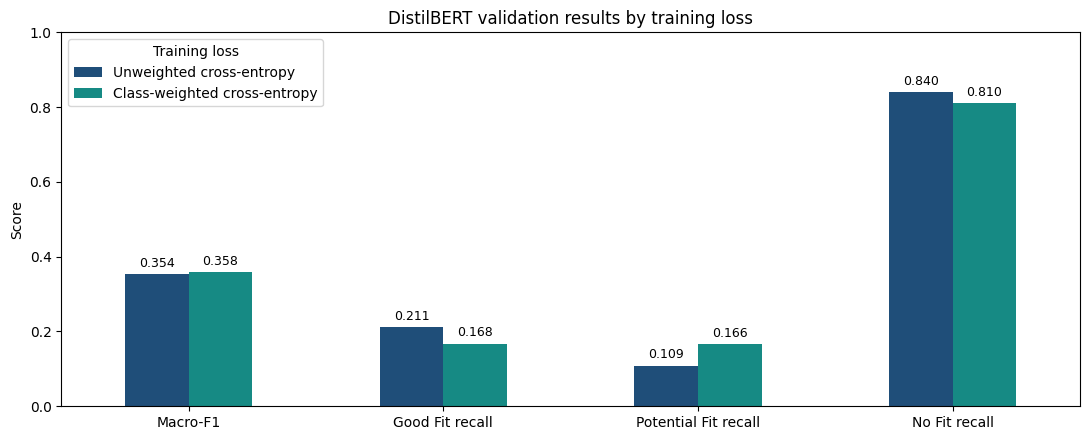

Figure saved to: /content/m4_training/distilbert_weighted_v1/comparison/loss_comparison.png


In [72]:
plot_columns = [
    "Validation macro-F1",
    "Good Fit recall",
    "Potential Fit recall",
    "No Fit recall"
]

weighted_plot_data = weighted_comparison_df.set_index("Loss")[plot_columns].T
weighted_plot_data.index = [
    "Macro-F1", "Good Fit recall", "Potential Fit recall", "No Fit recall"
]

ax = weighted_plot_data.plot(
    kind="bar",
    figsize=(11, 4.5),
    color=["#1F4E79", "#168A84"],
    rot=0
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("DistilBERT validation results by training loss")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.legend(title="Training loss")

figure = ax.get_figure()
figure.tight_layout()
weighted_figure_path = WEIGHTED_COMPARISON_DIR / "loss_comparison.png"
figure.savefig(weighted_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(figure)

print("Figure saved to:", weighted_figure_path)

In [73]:
weighted_comparison_notes = f"""# Class-Weighted DistilBERT Evaluation

## Experiment setup

Both runs start from the same pretrained DistilBERT checkpoint revision.
They use the same M3 source rows, labels, seed, original longest_first inputs,
512-token limit, and saved training arguments except the output directory.
No section-aware preparation is applied.

Class weights are calculated from training labels only:
training_rows / (number_of_classes * class_count).

The custom trainer computes weighted-mean cross-entropy within each microbatch.
It sets model_accepts_loss_kwargs=False so Trainer handles gradient accumulation.
Both runs select epoch 2 using validation macro-F1.

## Results

- Original validation macro-F1: {original_distilbert_metrics["validation_macro_f1"]:.4f}.
- Weighted validation macro-F1: {weighted_validation_output.metrics["validation_macro_f1"]:.4f}.
- Absolute macro-F1 change: {weighted_macro_f1_change:+.4f}.
- Accuracy falls from 0.4752 to 0.4673.
- Good Fit recall falls from 0.2107 to 0.1679.
- Potential Fit recall rises from 0.1088 to 0.1662.
- No Fit recall falls from 0.8396 to 0.8097.

The weighted model correctly identifies 47 Good Fit, 55 Potential Fit,
and 434 No Fit examples. Predicted counts are 160, 166, and 821 respectively.

## Interpretation

The weighted run has the highest validation macro-F1 among the recorded
DistilBERT variants, but its gain over the original is only 0.0042.
It improves Potential Fit recall while reducing Good Fit recall and accuracy.
Keep it as a candidate for further evaluation rather than declaring it
reliably better.

## Limitations and next steps

These are single-seed validation results. No repeated-run or statistical
uncertainty analysis establishes that the small gain is reliable.
The runs use different loss objectives, so their loss values are not directly
comparable. The custom trainer's loss normalisation is recorded explicitly.

Use error analysis, robustness checks, and inference measurements to assess
the candidates. Resolve the recall trade-offs before freezing model selection.
The official test set remains unevaluated.

Class weights and the custom loss are needed to reproduce training.
Inference uses the saved classifier with the original M3 text preparation
and paired tokenization.
"""

weighted_notes_path = WEIGHTED_COMPARISON_DIR / "comparison_notes.md"
weighted_notes_path.write_text(
    weighted_comparison_notes, encoding="utf-8"
)

print("Findings and limitations saved to:", weighted_notes_path)

Findings and limitations saved to: /content/m4_training/distilbert_weighted_v1/comparison/comparison_notes.md


In [74]:
saved_weighted_predictions = pd.read_csv(
    WEIGHTED_REPORT_DIR / "validation_predictions.csv"
)
saved_weighted_metrics = json.loads(
    (WEIGHTED_REPORT_DIR / "validation_metrics.json").read_text()
)
saved_weighted_confusion = pd.read_csv(
    WEIGHTED_REPORT_DIR / "validation_confusion_matrix.csv",
    index_col=0
)

np.testing.assert_array_equal(
    saved_weighted_predictions["source_row_id"],
    validation_df["source_row_id"].to_numpy()
)
np.testing.assert_array_equal(
    saved_weighted_predictions["true_label"],
    validation_df["label"].to_numpy()
)
np.testing.assert_array_equal(
    saved_weighted_predictions["predicted_label"],
    weighted_prediction_report["predicted_label"].to_numpy()
)

recomputed_weighted_f1 = f1_score(
    saved_weighted_predictions["true_label"],
    saved_weighted_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)
np.testing.assert_allclose(
    recomputed_weighted_f1,
    saved_weighted_metrics["validation_macro_f1"],
    rtol=1e-12
)
np.testing.assert_array_equal(
    confusion_matrix(
        saved_weighted_predictions["true_label"],
        saved_weighted_predictions["predicted_label"],
        labels=LABELS
    ),
    saved_weighted_confusion.to_numpy()
)
pd.testing.assert_frame_equal(
    pd.read_csv(WEIGHTED_COMPARISON_DIR / "loss_comparison.csv"),
    weighted_comparison_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

assert json.loads(
    (WEIGHTED_REPORT_DIR / "reload_check.json").read_text()
)["passed"]
assert weighted_run_summary["official_test_evaluated"] is False

print("Saved source rows, predictions, metrics, and confusion matrix match.")
print("Comparison CSV and model reload checks passed.")
print("Official test set remains unevaluated.")

Saved source rows, predictions, metrics, and confusion matrix match.
Comparison CSV and model reload checks passed.
Official test set remains unevaluated.


In [75]:
weighted_reports_archive = Path(
    "/content/distilbert_weighted_v1_reports.zip"
)
weighted_model_archive = Path(
    "/content/distilbert_weighted_v1_model.zip"
)

with ZipFile(weighted_reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(WEIGHTED_REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, path.name)

    for path in sorted(WEIGHTED_COMPARISON_DIR.iterdir()):
        if path.is_file():
            archive.write(path, f"comparison/{path.name}")

weighted_model_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json"
]

with ZipFile(weighted_model_archive, "w", ZIP_DEFLATED) as archive:
    for filename in weighted_model_files:
        path = WEIGHTED_MODEL_DIR / filename
        assert path.exists(), filename
        archive.write(path, filename)

    archive.write(
        WEIGHTED_REPORT_DIR / "weighted_run_config.json",
        "weighted_run_config.json"
    )

for path in [weighted_reports_archive, weighted_model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(
            f"{path.name}: {len(archive.namelist())} files, "
            f"{path.stat().st_size / 1024**2:.2f} MB"
        )

files.download(str(weighted_reports_archive))
files.download(str(weighted_model_archive))

distilbert_weighted_v1_reports.zip: 14 files, 0.11 MB
distilbert_weighted_v1_model.zip: 5 files, 235.75 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Compare all validation candidates

Collect five validation runs before final model selection. Do not use official-test results to choose a candidate.


In [76]:
final_comparison_rows = comparison_df.to_dict("records")

for model_name, metrics in [
    ("DistilBERT section-aware", section_validation_output.metrics),
    ("DistilBERT class-weighted", weighted_validation_output.metrics)
]:
    final_comparison_rows.append({
        "Model": model_name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"]
    })

final_comparison_df = (
    pd.DataFrame(final_comparison_rows)
    .sort_values("Validation macro-F1", ascending=False)
    .reset_index(drop=True)
)

assert len(final_comparison_df) == 5
assert final_comparison_df["Model"].is_unique
assert weighted_run_summary["official_test_evaluated"] is False
assert section_run_summary["official_test_evaluated"] is False
assert original_distilbert_summary["official_test_evaluated"] is False

FINAL_EVALUATION_DIR = Path("/content/m4_final_evaluation")
FINAL_EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

final_comparison_df.to_csv(
    FINAL_EVALUATION_DIR / "validation_model_comparison.csv",
    index=False
)

display(final_comparison_df.round(4))
print("Five validation runs recorded.")
print("Model selection is still open. Official test evaluation has not started.")

,Model,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,DistilBERT class-weighted,0.3582,0.4673,0.1679,0.1662,0.8097
1,DistilBERT,0.3540,0.4752,0.2107,0.1088,0.8396
2,DistilBERT section-aware,0.3258,0.4786,0.0500,0.1813,0.8862
3,MiniLM,0.3081,0.4682,0.2643,0.0000,0.8638
4,TF-IDF + SGD,0.2923,0.4429,0.0143,0.1964,0.8190


Five validation runs recorded.
Model selection is still open. Official test evaluation has not started.


## Reproduce original DistilBERT predictions

Load the saved original model and check its validation confusion matrix against M3 before paired error analysis.


In [77]:
ORIGINAL_MODEL_DIR = Path("/content/m4_models/original_distilbert")
required_model_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json"
]

if all((ORIGINAL_MODEL_DIR / name).exists() for name in required_model_files):
    print("Reusing the extracted original model.")
else:
    original_model_upload = files.upload()
    assert len(original_model_upload) == 1, (
        "Upload only distilbert_v1_model.zip."
    )

    archive_bytes = next(iter(original_model_upload.values()))

    with ZipFile(io.BytesIO(archive_bytes)) as archive:
        assert set(archive.namelist()) == set(required_model_files)
        assert archive.testzip() is None

        saved_config = json.loads(archive.read("config.json"))
        assert saved_config["model_type"] == "distilbert"
        assert saved_config["label2id"] == LABEL2ID

        ORIGINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)
        for filename in required_model_files:
            (ORIGINAL_MODEL_DIR / filename).write_bytes(
                archive.read(filename)
            )

    print("Original model extracted successfully.")

print("Model directory:", ORIGINAL_MODEL_DIR)
print("No training or official-test evaluation has been performed.")

Saving distilbert_v1_model.zip to distilbert_v1_model.zip
Original model extracted successfully.
Model directory: /content/m4_models/original_distilbert
No training or official-test evaluation has been performed.


In [78]:
weighted_trainer.model.to("cpu")

if weighted_trainer.optimizer is not None:
    for state in weighted_trainer.optimizer.state.values():
        for key, value in list(state.items()):
            if torch.is_tensor(value):
                state[key] = value.cpu()

torch.cuda.empty_cache()

final_original_tokenizer = AutoTokenizer.from_pretrained(
    str(ORIGINAL_MODEL_DIR), local_files_only=True
)
final_original_model = AutoModelForSequenceClassification.from_pretrained(
    str(ORIGINAL_MODEL_DIR), local_files_only=True
).to("cuda")
final_original_model.eval()

assert final_original_model.config.label2id == LABEL2ID
assert final_original_model.config.id2label == ID2LABEL
assert final_original_tokenizer.get_vocab() == weighted_tokenizer.get_vocab()
assert final_original_tokenizer.special_tokens_map == (
    weighted_tokenizer.special_tokens_map
)

print("Original model device:", next(final_original_model.parameters()).device)
print("Weighted model device:", next(weighted_trainer.model.parameters()).device)
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print("Original model loaded for validation inference.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Original model device: cuda:0
Weighted model device: cpu
GPU memory allocated: 0.27 GB
Original model loaded for validation inference.


In [79]:
from torch.utils.data import DataLoader


def predict_tokenized(model, data, batch_size=16, description="Inference"):
    loader = DataLoader(
        data,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=weighted_collator
    )
    device = next(model.parameters()).device
    assert device.type == "cuda"
    model.eval()
    logits_batches = []

    with torch.inference_mode():
        for batch in tqdm(loader, desc=description):
            inputs = {
                key: value.to(device)
                for key, value in batch.items()
                if key != "labels"
            }
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(**inputs).logits
            logits_batches.append(logits.float().cpu().numpy())

    return np.concatenate(logits_batches, axis=0)


original_validation_logits = predict_tokenized(
    final_original_model,
    weighted_datasets["Validation"],
    description="Original model validation"
)
original_validation_predictions = original_validation_logits.argmax(axis=-1)

original_recomputed_f1 = f1_score(
    validation_df["labels"],
    original_validation_predictions,
    labels=list(range(len(LABELS))),
    average="macro",
    zero_division=0
)

np.testing.assert_allclose(
    original_recomputed_f1,
    original_distilbert_metrics["validation_macro_f1"],
    rtol=1e-12
)
np.testing.assert_array_equal(
    confusion_matrix(
        validation_df["labels"],
        original_validation_predictions,
        labels=list(range(len(LABELS)))
    ),
    [[59, 2, 219], [89, 36, 206], [56, 30, 450]]
)

print(f"Reproduced original validation macro-F1: {original_recomputed_f1:.4f}")
print("Original confusion matrix matches the recorded M3 result.")

Original model validation:   0%|          | 0/72 [00:00<?, ?it/s]

Reproduced original validation macro-F1: 0.3540
Original confusion matrix matches the recorded M3 result.


## Review paired validation errors

Separate fixes, regressions and cases both models miss. Review 30 reproducibly selected cases; they are a qualitative sample, not a prevalence estimate.


In [80]:
candidate_predictions = pd.DataFrame({
    "source_row_id": validation_df["source_row_id"].to_numpy(),
    "true_label": validation_df["label"].to_numpy(),
    "original_prediction": [
        ID2LABEL[int(i)] for i in original_validation_predictions
    ],
    "weighted_prediction": [
        ID2LABEL[int(i)] for i in weighted_validation_predictions
    ]
})

candidate_predictions["original_correct"] = (
    candidate_predictions["original_prediction"]
    == candidate_predictions["true_label"]
)
candidate_predictions["weighted_correct"] = (
    candidate_predictions["weighted_prediction"]
    == candidate_predictions["true_label"]
)
candidate_predictions["weighted_fixed"] = (
    ~candidate_predictions["original_correct"]
    & candidate_predictions["weighted_correct"]
)
candidate_predictions["weighted_regression"] = (
    candidate_predictions["original_correct"]
    & ~candidate_predictions["weighted_correct"]
)
candidate_predictions["both_wrong"] = (
    ~candidate_predictions["original_correct"]
    & ~candidate_predictions["weighted_correct"]
)

paired_error_summary = (
    candidate_predictions.groupby("true_label")[
        ["original_correct", "weighted_correct",
         "weighted_fixed", "weighted_regression", "both_wrong"]
    ]
    .sum()
    .reindex(LABELS)
)

candidate_predictions.to_csv(
    FINAL_EVALUATION_DIR / "validation_candidate_predictions.csv",
    index=False
)
paired_error_summary.to_csv(
    FINAL_EVALUATION_DIR / "paired_error_summary.csv"
)

display(paired_error_summary)
print("Fixed: original wrong, weighted correct.")
print("Regression: original correct, weighted wrong.")

,original_correct,weighted_correct,weighted_fixed,weighted_regression,both_wrong
true_label,,,,,
Good Fit,59,47,12,24,209
Potential Fit,36,55,31,12,264
No Fit,450,434,16,32,70


Fixed: original wrong, weighted correct.
Regression: original correct, weighted wrong.


In [81]:
review_parts = []

for label in LABELS:
    class_cases = candidate_predictions[
        candidate_predictions["true_label"] == label
    ]

    for case_type, count in [
        ("weighted_regression", 4),
        ("both_wrong", 4),
        ("weighted_fixed", 2)
    ]:
        pool = class_cases[class_cases[case_type]]
        assert len(pool) >= count

        selected = pool.sample(n=count, random_state=SEED).copy()
        selected["case_type"] = case_type
        review_parts.append(selected)

error_review_sample = (
    pd.concat(review_parts, ignore_index=True)
    .sort_values(["true_label", "case_type", "source_row_id"])
    .reset_index(drop=True)
)

assert len(error_review_sample) == 30
assert error_review_sample["source_row_id"].is_unique

error_review_sample["review_category"] = ""
error_review_sample["evidence_notes"] = ""

error_review_sample.to_csv(
    FINAL_EVALUATION_DIR / "error_review_sample.csv",
    index=False
)

display(pd.crosstab(
    error_review_sample["true_label"],
    error_review_sample["case_type"]
).reindex(LABELS))

print("30 review cases selected reproducibly.")
print("Content-based causes have not been assigned yet.")

case_type,both_wrong,weighted_fixed,weighted_regression
true_label,,,
Good Fit,4,2,4
Potential Fit,4,2,4
No Fit,4,2,4


30 review cases selected reproducibly.
Content-based causes have not been assigned yet.


## Keep source-text review files private

The text-containing review file stays outside exported reports. Import reviewed categories and exclude document text from final artifacts.


In [82]:
PRIVATE_REVIEW_DIR = Path("/content/m4_private_review")
PRIVATE_REVIEW_DIR.mkdir(parents=True, exist_ok=True)

private_review = error_review_sample.merge(
    validation_df[
        ["source_row_id", "resume_model_text", "job_model_text"]
    ],
    on="source_row_id",
    how="left",
    validate="one_to_one"
)

validation_positions = {
    int(source_id): position
    for position, source_id in enumerate(validation_df["source_row_id"])
}

private_review["visible_model_input"] = [
    weighted_tokenizer.decode(
        weighted_datasets["Validation"][
            validation_positions[int(source_id)]
        ]["input_ids"],
        skip_special_tokens=False
    )
    for source_id in private_review["source_row_id"]
]

assert len(private_review) == 30
assert private_review[
    ["resume_model_text", "job_model_text", "visible_model_input"]
].notna().all().all()

private_review_path = (
    PRIVATE_REVIEW_DIR / "error_review_with_text.csv"
)
private_review.to_csv(private_review_path, index=False)

print("Review cases:", len(private_review))
print("Saved to:", private_review_path)
files.download(str(private_review_path))

Review cases: 30
Saved to: /content/m4_private_review/error_review_with_text.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [83]:
review_upload = files.upload()

required_review_files = {
    "error_review_annotations.csv",
    "error_review_findings.md"
}
assert set(review_upload) == required_review_files

reviewed_error_cases = pd.read_csv(
    io.BytesIO(review_upload["error_review_annotations.csv"]),
    keep_default_na=False
)

assert len(reviewed_error_cases) == 30
assert reviewed_error_cases["source_row_id"].is_unique

identity_columns = [
    "source_row_id", "true_label", "original_prediction",
    "weighted_prediction", "case_type"
]
expected_cases = error_review_sample.sort_values("source_row_id")
received_cases = reviewed_error_cases.sort_values("source_row_id")

for column in identity_columns:
    np.testing.assert_array_equal(
        received_cases[column].to_numpy(),
        expected_cases[column].to_numpy()
    )

for column in ["review_category", "evidence_notes"]:
    assert reviewed_error_cases[column].str.strip().ne("").all()

assert not {
    "resume_model_text", "job_model_text", "visible_model_input"
}.intersection(reviewed_error_cases.columns)

for filename in required_review_files:
    (FINAL_EVALUATION_DIR / filename).write_bytes(review_upload[filename])

error_review_sample = reviewed_error_cases.copy()
(FINAL_EVALUATION_DIR / "error_review_sample.csv").unlink(missing_ok=True)

display(error_review_sample["review_category"].value_counts().to_frame("Cases"))
print("Reviewed annotations verified and saved.")
print("The text-containing review file remains outside the final reports.")

Saving error_review_annotations.csv to error_review_annotations.csv
Saving error_review_findings.md to error_review_findings.md


,Cases
review_category,
specialist_requirements_not_established,15
label_evidence_tension,7
input_context_loss,5
text_quality_or_profile_conflict,3


Reviewed annotations verified and saved.
The text-containing review file remains outside the final reports.


## Fix the robustness sample and transformations

Use 300 validation pairs with 100 per label. Formatting checks and content-changing stress tests answer different questions.


In [84]:
ROBUSTNESS_ROWS_PER_CLASS = 100

robustness_sample_df = (
    validation_df.groupby("label", group_keys=False, sort=False)
    .sample(n=ROBUSTNESS_ROWS_PER_CLASS, random_state=SEED)
    .sort_values("source_row_id")
    .reset_index(drop=True)
)

assert len(robustness_sample_df) == 300
assert robustness_sample_df["source_row_id"].is_unique
assert robustness_sample_df["label"].value_counts().eq(100).all()

ROBUSTNESS_PROTOCOL = {
    "original": "Unchanged reference inputs",
    "extra_whitespace": "Meaning-preserving formatting check",
    "case_change": "Meaning-preserving letter-case check",
    "block_order": "Stress test: reorder document blocks",
    "skills_removed": "Stress test: remove recognised resume skills blocks",
    "long_prefix": "Stress test: prepend unrelated review boilerplate"
}

robustness_manifest = {
    "seed": SEED,
    "source_split": "Validation",
    "sampling": "100 examples per true class",
    "source_row_ids": robustness_sample_df["source_row_id"].astype(int).tolist(),
    "class_counts": {
        label: int(count)
        for label, count in robustness_sample_df["label"].value_counts().items()
    },
    "variants": ROBUSTNESS_PROTOCOL,
    "note": "Balanced stress sample; not the natural validation distribution"
}

(FINAL_EVALUATION_DIR / "robustness_manifest.json").write_text(
    json.dumps(robustness_manifest, indent=2), encoding="utf-8"
)

display(
    robustness_sample_df["label"]
    .value_counts()
    .reindex(LABELS)
    .to_frame("Pairs")
)
display(pd.Series(ROBUSTNESS_PROTOCOL, name="Purpose").to_frame())
print("Robustness sample fixed. Official test data is not used.")

,Pairs
label,
Good Fit,100
Potential Fit,100
No Fit,100


,Purpose
original,Unchanged reference inputs
extra_whitespace,Meaning-preserving formatting check
case_change,Meaning-preserving letter-case check
block_order,Stress test: reorder document blocks
skills_removed,Stress test: remove recognised resume skills b...
long_prefix,Stress test: prepend unrelated review boilerplate


Robustness sample fixed. Official test data is not used.


In [85]:
import string

ASCII_UPPERCASE = str.maketrans(
    string.ascii_lowercase, string.ascii_uppercase
)
REVIEW_BOILERPLATE = "Document provided for recruitment review. " * 80


def remove_resume_skills(text):
    kept_lines = []
    inside_skills = False

    for line in text.splitlines():
        section_name, _ = parse_section_heading(line)
        if section_name is not None:
            inside_skills = section_name == "skills"
        if not inside_skills:
            kept_lines.append(line)

    return "\n".join(kept_lines).strip()


def make_robust_pair(resume, job, variant):
    assert variant in ROBUSTNESS_PROTOCOL

    if variant == "extra_whitespace":
        resume = re.sub(r"\s+", "   \n\n   ", resume)
        job = re.sub(r"\s+", "   \n\n   ", job)
    elif variant == "case_change":
        resume = resume.translate(ASCII_UPPERCASE)
        job = job.translate(ASCII_UPPERCASE)

    resume, job = prepare_text(resume), prepare_text(job)

    if variant == "block_order":
        resume = "\n".join(reversed(resume.splitlines()))
        job = "\n".join(reversed(job.splitlines()))
    elif variant == "skills_removed":
        resume = remove_resume_skills(resume)
    elif variant == "long_prefix":
        resume = REVIEW_BOILERPLATE + resume

    return resume, job


probe_text = "SummaryDeveloper\nSkillsPython\nSQL\nExperienceBuilt APIs"
probe_without_skills = remove_resume_skills(probe_text)

assert "Python" not in probe_without_skills
assert "SQL" not in probe_without_skills
assert "ExperienceBuilt APIs" in probe_without_skills

print("Robustness transformations are ready.")
print("Skills removal uses the recorded heading rules.")
print("Long-prefix stress adds boilerplate to the resume only.")

Robustness transformations are ready.
Skills removal uses the recorded heading rules.
Long-prefix stress adds boilerplate to the resume only.


In [86]:
robustness_datasets = DatasetDict()
robustness_text_changes = {}
robustness_empty_resumes = {}


def tokenize_robustness_batch(batch):
    return weighted_tokenizer(
        batch["resume"],
        batch["job"],
        truncation="longest_first",
        max_length=512,
        padding=False,
        return_token_type_ids=False,
        return_attention_mask=True
    )


for variant in ROBUSTNESS_PROTOCOL:
    pairs = [
        make_robust_pair(row.resume_text, row.job_description_text, variant)
        for row in robustness_sample_df.itertuples(index=False)
    ]
    resumes, jobs = map(list, zip(*pairs))

    robustness_text_changes[variant] = [
        resume != original_resume or job != original_job
        for resume, job, original_resume, original_job in zip(
            resumes, jobs,
            robustness_sample_df["resume_model_text"],
            robustness_sample_df["job_model_text"]
        )
    ]
    robustness_empty_resumes[variant] = sum(
        not resume.strip() for resume in resumes
    )

    source_data = Dataset.from_dict({
        "resume": resumes,
        "job": jobs,
        "labels": robustness_sample_df["labels"].astype(int).tolist()
    })
    robustness_datasets[variant] = source_data.map(
        tokenize_robustness_batch,
        batched=True,
        remove_columns=["resume", "job"],
        desc=f"Robustness: {variant}"
    )

    np.testing.assert_array_equal(
        robustness_datasets[variant]["labels"],
        robustness_sample_df["labels"].to_numpy()
    )
    print(variant, len(robustness_datasets[variant]), "pairs")

print("All variants prepared. No model inference has started on them.")

Robustness: original:   0%|          | 0/300 [00:00<?, ? examples/s]

original 300 pairs


Robustness: extra_whitespace:   0%|          | 0/300 [00:00<?, ? examples/s]

extra_whitespace 300 pairs


Robustness: case_change:   0%|          | 0/300 [00:00<?, ? examples/s]

case_change 300 pairs


... (2 outputs left out)

Robustness: skills_removed:   0%|          | 0/300 [00:00<?, ? examples/s]

skills_removed 300 pairs


Robustness: long_prefix:   0%|          | 0/300 [00:00<?, ? examples/s]

long_prefix 300 pairs
All variants prepared. No model inference has started on them.


## Verify transformed inputs and run inference

Compare tokenized inputs first. Identical inputs reuse predictions; this does not demonstrate semantic understanding.


In [87]:
robustness_validation_positions = [
    validation_positions[int(source_id)]
    for source_id in robustness_sample_df["source_row_id"]
]
expected_original_inputs = weighted_datasets["Validation"].select(
    robustness_validation_positions
)

baseline_robust_ids = list(robustness_datasets["original"]["input_ids"])

assert baseline_robust_ids == list(expected_original_inputs["input_ids"])
assert not any(robustness_text_changes["original"])

robustness_input_rows = []

for variant, data in robustness_datasets.items():
    input_ids = list(data["input_ids"])
    lengths = [len(ids) for ids in input_ids]
    changed_count = sum(
        ids != baseline_ids
        for ids, baseline_ids in zip(input_ids, baseline_robust_ids)
    )

    assert len(data) == 300
    assert all(3 <= length <= 512 for length in lengths)

    robustness_input_rows.append({
        "Variant": variant,
        "Pairs": len(data),
        "Prepared text changed": sum(robustness_text_changes[variant]),
        "Tokenized inputs changed": changed_count,
        "Empty resumes": robustness_empty_resumes[variant],
        "Minimum tokens": min(lengths),
        "Maximum tokens": max(lengths)
    })

robustness_input_report = pd.DataFrame(robustness_input_rows)
robustness_input_report.to_csv(
    FINAL_EVALUATION_DIR / "robustness_input_checks.csv",
    index=False
)

display(robustness_input_report)
print("Original inputs match the corresponding validation rows exactly.")

,Variant,Pairs,Prepared text changed,Tokenized inputs changed,Empty resumes,Minimum tokens,Maximum tokens
0,original,300,0,0,0,437,512
1,extra_whitespace,300,300,0,0,437,512
2,case_change,300,300,0,0,437,512
3,block_order,300,300,300,0,437,512
4,skills_removed,300,234,133,0,384,512
5,long_prefix,300,300,300,0,512,512


Original inputs match the corresponding validation rows exactly.


In [88]:
original_robustness_logits = {
    "original": original_validation_logits[
        robustness_validation_positions
    ].copy()
}
original_robustness_reused = {"original": True}

assert next(final_original_model.parameters()).device.type == "cuda"

for variant, data in robustness_datasets.items():
    if variant == "original":
        continue

    identical_inputs = (
        list(data["input_ids"]) == baseline_robust_ids
    )

    if identical_inputs:
        original_robustness_logits[variant] = (
            original_robustness_logits["original"].copy()
        )
    else:
        original_robustness_logits[variant] = predict_tokenized(
            final_original_model,
            data,
            description=f"Original: {variant}"
        )

    original_robustness_reused[variant] = identical_inputs
    assert original_robustness_logits[variant].shape == (300, 3)

original_robustness_baseline = (
    original_robustness_logits["original"].argmax(axis=-1)
)

for variant, logits in original_robustness_logits.items():
    flips = int(
        (logits.argmax(axis=-1) != original_robustness_baseline).sum()
    )
    print(
        f"{variant}: {flips}/300 prediction changes; "
        f"reused identical inputs: {original_robustness_reused[variant]}"
    )

print("Original-model robustness inference finished.")

Original: block_order:   0%|          | 0/19 [00:00<?, ?it/s]

Original: skills_removed:   0%|          | 0/19 [00:00<?, ?it/s]

Original: long_prefix:   0%|          | 0/19 [00:00<?, ?it/s]

original: 0/300 prediction changes; reused identical inputs: True
extra_whitespace: 0/300 prediction changes; reused identical inputs: True
case_change: 0/300 prediction changes; reused identical inputs: True
block_order: 47/300 prediction changes; reused identical inputs: False
skills_removed: 13/300 prediction changes; reused identical inputs: False
long_prefix: 80/300 prediction changes; reused identical inputs: False
Original-model robustness inference finished.


In [89]:
final_original_model.to("cpu")
weighted_trainer.model.to("cuda")
torch.cuda.empty_cache()

weighted_robustness_logits = {
    "original": weighted_validation_output.predictions[
        robustness_validation_positions
    ].copy()
}
weighted_robustness_reused = {"original": True}

np.testing.assert_array_equal(
    weighted_robustness_logits["original"].argmax(axis=-1),
    weighted_validation_predictions[robustness_validation_positions]
)

for variant, data in robustness_datasets.items():
    if variant == "original":
        continue

    identical_inputs = (
        list(data["input_ids"]) == baseline_robust_ids
    )

    if identical_inputs:
        weighted_robustness_logits[variant] = (
            weighted_robustness_logits["original"].copy()
        )
    else:
        weighted_robustness_logits[variant] = predict_tokenized(
            weighted_trainer.model,
            data,
            description=f"Weighted: {variant}"
        )

    weighted_robustness_reused[variant] = identical_inputs
    assert weighted_robustness_logits[variant].shape == (300, 3)

weighted_robustness_baseline = (
    weighted_robustness_logits["original"].argmax(axis=-1)
)

for variant, logits in weighted_robustness_logits.items():
    flips = int(
        (logits.argmax(axis=-1) != weighted_robustness_baseline).sum()
    )
    print(
        f"{variant}: {flips}/300 prediction changes; "
        f"reused identical inputs: {weighted_robustness_reused[variant]}"
    )

print("Weighted-model robustness inference finished.")

Weighted: block_order:   0%|          | 0/19 [00:00<?, ?it/s]

Weighted: skills_removed:   0%|          | 0/19 [00:00<?, ?it/s]

Weighted: long_prefix:   0%|          | 0/19 [00:00<?, ?it/s]

original: 0/300 prediction changes; reused identical inputs: True
extra_whitespace: 0/300 prediction changes; reused identical inputs: True
case_change: 0/300 prediction changes; reused identical inputs: True
block_order: 68/300 prediction changes; reused identical inputs: False
skills_removed: 14/300 prediction changes; reused identical inputs: False
long_prefix: 93/300 prediction changes; reused identical inputs: False
Weighted-model robustness inference finished.


## Report sensitivity to stress tests

Report prediction-change rates, including the rate among changed inputs. Skills removal and unrelated prefixes can change meaning, so these are not accuracy tests.


In [90]:
robustness_result_rows = []
robustness_prediction_frames = []

for model_name, variant_logits in [
    ("DistilBERT", original_robustness_logits),
    ("DistilBERT class-weighted", weighted_robustness_logits)
]:
    baseline_predictions = variant_logits["original"].argmax(axis=-1)

    for variant, logits in variant_logits.items():
        predictions = logits.argmax(axis=-1)
        changed_inputs = np.array([
            ids != baseline_ids
            for ids, baseline_ids in zip(
                robustness_datasets[variant]["input_ids"],
                baseline_robust_ids
            )
        ])
        prediction_changes = predictions != baseline_predictions
        changed_count = int(changed_inputs.sum())

        robustness_result_rows.append({
            "Model": model_name,
            "Variant": variant,
            "Pairs": len(predictions),
            "Changed inputs": changed_count,
            "Prediction changes": int(prediction_changes.sum()),
            "Change rate (%)": 100 * prediction_changes.mean(),
            "Change rate on changed inputs (%)": (
                100 * prediction_changes[changed_inputs].mean()
                if changed_count else np.nan
            ),
            "Unchanged-input flips": int(
                prediction_changes[~changed_inputs].sum()
            )
        })

        robustness_prediction_frames.append(pd.DataFrame({
            "Model": model_name,
            "Variant": variant,
            "source_row_id": robustness_sample_df["source_row_id"].to_numpy(),
            "baseline_prediction": [ID2LABEL[int(i)] for i in baseline_predictions],
            "prediction": [ID2LABEL[int(i)] for i in predictions],
            "input_changed": changed_inputs,
            "prediction_changed": prediction_changes
        }))

robustness_results = pd.DataFrame(robustness_result_rows)
robustness_predictions = pd.concat(
    robustness_prediction_frames, ignore_index=True
)

robustness_results.to_csv(
    FINAL_EVALUATION_DIR / "robustness_results.csv", index=False
)
robustness_predictions.to_csv(
    FINAL_EVALUATION_DIR / "robustness_predictions.csv", index=False
)

display(robustness_results.round(2))
print("Content-changing stress tests are reported as sensitivity, not accuracy.")

,Model,Variant,Pairs,Changed inputs,Prediction changes,Change rate (%),Change rate on changed inputs (%),Unchanged-input flips
0,DistilBERT,original,300,0,0,0.00,NaN,0
1,DistilBERT,extra_whitespace,300,0,0,0.00,NaN,0
2,DistilBERT,case_change,300,0,0,0.00,NaN,0
3,DistilBERT,block_order,300,300,47,15.67,15.67,0
4,DistilBERT,skills_removed,300,133,13,4.33,9.77,0
5,DistilBERT,long_prefix,300,300,80,26.67,26.67,0
6,DistilBERT class-weighted,original,300,0,0,0.00,NaN,0
7,DistilBERT class-weighted,extra_whitespace,300,0,0,0.00,NaN,0
8,DistilBERT class-weighted,case_change,300,0,0,0.00,NaN,0
9,DistilBERT class-weighted,block_order,300,300,68,22.67,22.67,0


Content-changing stress tests are reported as sensitivity, not accuracy.


## Benchmark model-only GPU inference

Measure each candidate separately with warmup, synchronized timing and memory tracking. Exclude upload, tokenization, network and UI time from these measurements.


In [91]:
INFERENCE_WARMUP = 3
INFERENCE_REPEATS = 30

benchmark_positions = np.random.default_rng(SEED).choice(
    len(robustness_sample_df), size=16, replace=False
)
inference_batches = {}

for batch_size in [1, 16]:
    batch = weighted_collator([
        robustness_datasets["original"][int(position)]
        for position in benchmark_positions[:batch_size]
    ])
    inference_batches[batch_size] = {
        key: value for key, value in batch.items()
        if key != "labels"
    }

weighted_trainer.model.to("cpu")
torch.cuda.empty_cache()

final_weighted_model = AutoModelForSequenceClassification.from_pretrained(
    str(WEIGHTED_MODEL_DIR), local_files_only=True
).to("cuda")
final_weighted_model.eval()

assert final_weighted_model.config.label2id == LABEL2ID

inference_protocol = {
    "device": torch.cuda.get_device_name(0),
    "precision": "FP16 autocast; FP32 model weights",
    "batch_sizes": [1, 16],
    "warmup_batches": INFERENCE_WARMUP,
    "timed_batches": INFERENCE_REPEATS,
    "source_split": "Validation",
    "source_row_ids": robustness_sample_df.iloc[
        benchmark_positions
    ]["source_row_id"].astype(int).tolist(),
    "timing_scope": "Model forward pass with inputs already on GPU",
    "excluded": "Text preparation, tokenization, transfers, and response handling",
    "limitation": "Repeated fixed batches on one Colab GPU"
}

(FINAL_EVALUATION_DIR / "inference_protocol.json").write_text(
    json.dumps(inference_protocol, indent=2), encoding="utf-8"
)

for size, batch in inference_batches.items():
    print("Batch size:", size, "Input shape:", tuple(batch["input_ids"].shape))

print("Warmup batches:", INFERENCE_WARMUP)
print("Timed batches:", INFERENCE_REPEATS)
print("Saved weighted model loaded without the training wrapper.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Batch size: 1 Input shape: (1, 512)
Batch size: 16 Input shape: (16, 512)
Warmup batches: 3
Timed batches: 30
Saved weighted model loaded without the training wrapper.


In [92]:
def benchmark_forward(model, cpu_batch):
    gpu_batch = {
        key: value.to("cuda")
        for key, value in cpu_batch.items()
    }
    batch_size = gpu_batch["input_ids"].shape[0]
    model.eval()
    timings = []

    with torch.inference_mode():
        for _ in range(INFERENCE_WARMUP):
            with torch.autocast("cuda", dtype=torch.float16):
                output = model(**gpu_batch)
            del output

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        starting_memory = torch.cuda.memory_allocated()

        for _ in range(INFERENCE_REPEATS):
            torch.cuda.synchronize()
            started = time.perf_counter()

            with torch.autocast("cuda", dtype=torch.float16):
                output = model(**gpu_batch)

            torch.cuda.synchronize()
            timings.append(time.perf_counter() - started)
            del output

        peak_memory = torch.cuda.max_memory_allocated()

    statistics = {
        "Median batch ms": float(np.median(timings) * 1000),
        "P95 batch ms": float(np.percentile(timings, 95) * 1000),
        "Examples per second": float(batch_size / np.mean(timings)),
        "Peak allocated GB": peak_memory / 1024**3,
        "Additional peak GB": (peak_memory - starting_memory) / 1024**3
    }
    return statistics, timings


print("Inference benchmark function is ready.")
print("Each candidate will be measured separately on the GPU.")

Inference benchmark function is ready.
Each candidate will be measured separately on the GPU.


In [93]:
inference_result_rows = []
inference_timing_rows = []

for model_name, model in [
    ("DistilBERT class-weighted", final_weighted_model),
    ("DistilBERT", final_original_model)
]:
    model.to("cuda")
    print("Benchmarking:", model_name)

    for batch_size, cpu_batch in inference_batches.items():
        statistics, timings = benchmark_forward(model, cpu_batch)

        inference_result_rows.append({
            "Model": model_name,
            "Batch size": batch_size,
            **statistics
        })
        inference_timing_rows.extend({
            "Model": model_name,
            "Batch size": batch_size,
            "Repeat": repeat + 1,
            "Seconds": seconds
        } for repeat, seconds in enumerate(timings))

    model.to("cpu")
    torch.cuda.empty_cache()

inference_results = pd.DataFrame(inference_result_rows)
inference_timings = pd.DataFrame(inference_timing_rows)

assert len(inference_results) == 4
assert len(inference_timings) == 4 * INFERENCE_REPEATS

inference_results.to_csv(
    FINAL_EVALUATION_DIR / "inference_results.csv", index=False
)
inference_timings.to_csv(
    FINAL_EVALUATION_DIR / "inference_timings.csv", index=False
)

display(inference_results.round(3))
print("GPU forward-pass benchmark finished.")
print("These measurements exclude the rest of the application pipeline.")

Benchmarking: DistilBERT class-weighted
Benchmarking: DistilBERT


,Model,Batch size,Median batch ms,P95 batch ms,Examples per second,Peak allocated GB,Additional peak GB
0,DistilBERT class-weighted,1,8.804,22.064,93.596,0.282,0.014
1,DistilBERT class-weighted,16,47.271,48.602,337.781,0.431,0.164
2,DistilBERT,1,10.185,14.229,94.673,0.282,0.014
3,DistilBERT,16,47.894,52.491,330.391,0.431,0.164


GPU forward-pass benchmark finished.
These measurements exclude the rest of the application pipeline.


## Freeze selection before official-test evaluation

Record the selected weighted checkpoint and fixed comparators using validation evidence only. Preserve the recorded selection after seeing test results.


In [94]:
from datetime import datetime, timezone

SELECTION_PATH = FINAL_EVALUATION_DIR / "model_selection.json"
assert not SELECTION_PATH.exists(), (
    "A selection record already exists. Keep it rather than overwriting it."
)

selected_model_name = final_comparison_df.iloc[0]["Model"]
assert selected_model_name == "DistilBERT class-weighted"

with (WEIGHTED_MODEL_DIR / "model.safetensors").open("rb") as model_file:
    selected_weights_sha256 = hashlib.file_digest(
        model_file, "sha256"
    ).hexdigest()

model_selection = {
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
    "selection_rule": "Highest validation macro-F1 among recorded candidates",
    "selected_model": selected_model_name,
    "selected_run_id": "distilbert_weighted_v1",
    "selected_validation_macro_f1": float(
        weighted_validation_output.metrics["validation_macro_f1"]
    ),
    "selected_checkpoint": weighted_run_summary["best_checkpoint"],
    "selected_weights_sha256": selected_weights_sha256,
    "dataset_revision": split_manifest["dataset_revision"],
    "split_manifest_sha256": weighted_run_config["split_manifest_sha256"],
    "input_policy": weighted_run_config["input_policy"],
    "fixed_test_comparators": ["DistilBERT", "TF-IDF + SGD"],
    "prediction_rule": "Default argmax/classifier prediction; no threshold tuning",
    "tradeoffs": [
        "Small single-seed macro-F1 gain",
        "Lower Good Fit recall and accuracy than original DistilBERT",
        "More prediction changes in the tested stress variants"
    ],
    "test_rule": "Final reporting only; no selection or tuning from test results",
    "official_test_evaluated_at_freeze": False
}

SELECTION_PATH.write_text(
    json.dumps(model_selection, indent=2), encoding="utf-8"
)

print("Selection frozen:", model_selection["selected_model"])
print("Validation macro-F1:", round(
    model_selection["selected_validation_macro_f1"], 4
))
print("Fixed comparators:", model_selection["fixed_test_comparators"])
print("Selection record saved before official-test evaluation.")

Selection frozen: DistilBERT class-weighted
Validation macro-F1: 0.3582
Fixed comparators: ['DistilBERT', 'TF-IDF + SGD']
Selection record saved before official-test evaluation.


## Evaluate the frozen candidates on official test

Prepare test inputs without fitting or tuning. Report all fixed comparators even if the selected model does not score highest.


In [95]:
assert SELECTION_PATH.exists()
assert not (FINAL_EVALUATION_DIR / "official_test_metrics.csv").exists()

np.testing.assert_array_equal(
    test_df["source_row_id"].to_numpy(),
    split_manifest["source_row_ids"]["Official test"]
)
assert len(test_df) == 1759

final_test_source = Dataset.from_pandas(
    test_df[["resume_model_text", "job_model_text", "labels"]],
    preserve_index=False
)
final_test_dataset = final_test_source.map(
    tokenize_original_pairs,
    batched=True,
    remove_columns=["resume_model_text", "job_model_text"],
    desc="Frozen official-test inputs"
)

np.testing.assert_array_equal(
    final_test_dataset["labels"],
    test_df["labels"].to_numpy()
)
assert all(
    0 < len(ids) <= 512
    for ids in final_test_dataset["input_ids"]
)

final_test_pair_text = create_baseline_pairs(test_df)
assert len(final_test_pair_text) == len(final_test_dataset)

display(
    test_df["label"].value_counts()
    .reindex(LABELS)
    .to_frame("Official test examples")
)
print("Transformer test pairs:", len(final_test_dataset))
print("TF-IDF test pairs:", len(final_test_pair_text))
print("No fitting, threshold changes, or section selection was performed.")

Frozen official-test inputs:   0%|          | 0/1759 [00:00<?, ? examples/s]

,Official test examples
label,
Good Fit,458
Potential Fit,444
No Fit,857


Transformer test pairs: 1759
TF-IDF test pairs: 1759
No fitting, threshold changes, or section selection was performed.


In [96]:
assert not (FINAL_EVALUATION_DIR / "official_test_metrics.csv").exists()
frozen_selection = json.loads(SELECTION_PATH.read_text())

assert frozen_selection["selected_model"] == "DistilBERT class-weighted"

with (WEIGHTED_MODEL_DIR / "model.safetensors").open("rb") as model_file:
    assert hashlib.file_digest(model_file, "sha256").hexdigest() == (
        frozen_selection["selected_weights_sha256"]
    )

final_test_predictions = {}

for model_name, model in [
    ("DistilBERT class-weighted", final_weighted_model),
    ("DistilBERT", final_original_model)
]:
    model.to("cuda")

    logits = predict_tokenized(
        model,
        final_test_dataset,
        description=f"Official test: {model_name}"
    )
    final_test_predictions[model_name] = logits.argmax(axis=-1)

    model.to("cpu")
    torch.cuda.empty_cache()

reference_test_labels = reference_pipeline.predict(final_test_pair_text)
final_test_predictions["TF-IDF + SGD"] = np.array([
    LABEL2ID[label] for label in reference_test_labels
])

test_prediction_report = pd.DataFrame({
    "source_row_id": test_df["source_row_id"].to_numpy(),
    "true_label": test_df["label"].to_numpy()
})

for model_name, predictions in final_test_predictions.items():
    assert predictions.shape == (1759,)
    test_prediction_report[model_name] = [
        ID2LABEL[int(index)] for index in predictions
    ]

test_prediction_report.to_csv(
    FINAL_EVALUATION_DIR / "official_test_predictions.csv",
    index=False
)

print("Official-test predictions saved for all three frozen candidates.")
print("Selected model remains:", frozen_selection["selected_model"])

Official test: DistilBERT class-weighted:   0%|          | 0/110 [00:00<?, ?it/s]

Official test: DistilBERT:   0%|          | 0/110 [00:00<?, ?it/s]

Official-test predictions saved for all three frozen candidates.
Selected model remains: DistilBERT class-weighted


## Inspect test scores and class-level errors

Weighted DistilBERT remains the recorded selection; TF-IDF has the highest measured test macro-F1. Suitable-candidate recall remains weak.


In [97]:
test_metric_rows = []
test_report_folders = {
    "DistilBERT class-weighted": "distilbert-weighted-v1",
    "DistilBERT": "distilbert-v1",
    "TF-IDF + SGD": "tfidf-sgd-v1"
}
test_label_ids = test_df["labels"].to_numpy()

for model_name, predictions in final_test_predictions.items():
    report_dir = (
        FINAL_EVALUATION_DIR / "test_reports"
        / test_report_folders[model_name]
    )
    report_dir.mkdir(parents=True, exist_ok=True)

    class_report = pd.DataFrame(
        classification_report(
            test_label_ids, predictions,
            labels=list(range(len(LABELS))),
            target_names=LABELS,
            output_dict=True,
            zero_division=0
        )
    ).T.loc[LABELS]

    matrix = pd.DataFrame(
        confusion_matrix(
            test_label_ids, predictions,
            labels=list(range(len(LABELS)))
        ),
        index=pd.Index(LABELS, name="True label"),
        columns=pd.Index(LABELS, name="Predicted label")
    )

    class_report.to_csv(report_dir / "class_report.csv", index_label="label")
    matrix.to_csv(report_dir / "confusion_matrix.csv")

    test_metric_rows.append({
        "Model": model_name,
        "Role": (
            "Selected" if model_name == frozen_selection["selected_model"]
            else "Fixed comparator"
        ),
        "Test macro-F1": f1_score(
            test_label_ids, predictions,
            labels=list(range(len(LABELS))),
            average="macro", zero_division=0
        ),
        "Test accuracy": accuracy_score(test_label_ids, predictions),
        **{
            f"{label} recall": float(class_report.loc[label, "recall"])
            for label in LABELS
        }
    })

official_test_metrics = pd.DataFrame(test_metric_rows)
official_test_metrics.to_csv(
    FINAL_EVALUATION_DIR / "official_test_metrics.csv", index=False
)

display(official_test_metrics.round(4))
print("Final selection unchanged:", frozen_selection["selected_model"])

,Model,Role,Test macro-F1,Test accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,DistilBERT class-weighted,Selected,0.3563,0.4304,0.1921,0.2342,0.6593
1,DistilBERT,Fixed comparator,0.3626,0.4929,0.2555,0.0856,0.8308
2,TF-IDF + SGD,Fixed comparator,0.4058,0.5009,0.1856,0.2658,0.7911


Final selection unchanged: DistilBERT class-weighted


In [98]:
validation_test_comparison = official_test_metrics[
    ["Model", "Role", "Test macro-F1"]
].merge(
    final_comparison_df[["Model", "Validation macro-F1"]],
    on="Model",
    validate="one_to_one"
)
validation_test_comparison["Test minus validation"] = (
    validation_test_comparison["Test macro-F1"]
    - validation_test_comparison["Validation macro-F1"]
)
validation_test_comparison.to_csv(
    FINAL_EVALUATION_DIR / "validation_test_comparison.csv",
    index=False
)

selected_test_dir = (
    FINAL_EVALUATION_DIR / "test_reports" / "distilbert-weighted-v1"
)
selected_test_class_report = pd.read_csv(
    selected_test_dir / "class_report.csv", index_col=0
)
selected_test_confusion = pd.read_csv(
    selected_test_dir / "confusion_matrix.csv", index_col=0
)

assert selected_test_confusion.to_numpy().sum() == 1759
assert selected_test_confusion.sum(axis=1).tolist() == [458, 444, 857]

display(validation_test_comparison.round(4))
display(selected_test_class_report.round(4))
display(selected_test_confusion)
print("The test comparison is for reporting, not model reselection.")

,Model,Role,Test macro-F1,Validation macro-F1,Test minus validation
0,DistilBERT class-weighted,Selected,0.3563,0.3582,-0.0019
1,DistilBERT,Fixed comparator,0.3626,0.3540,0.0085
2,TF-IDF + SGD,Fixed comparator,0.4058,0.2923,0.1136


,precision,recall,f1-score,support
label,,,,
Good Fit,0.2581,0.1921,0.2203,458.0
Potential Fit,0.2751,0.2342,0.2530,444.0
No Fit,0.5433,0.6593,0.5957,857.0


,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,88,149,221
Potential Fit,86,104,254
No Fit,167,125,565


The test comparison is for reporting, not model reselection.


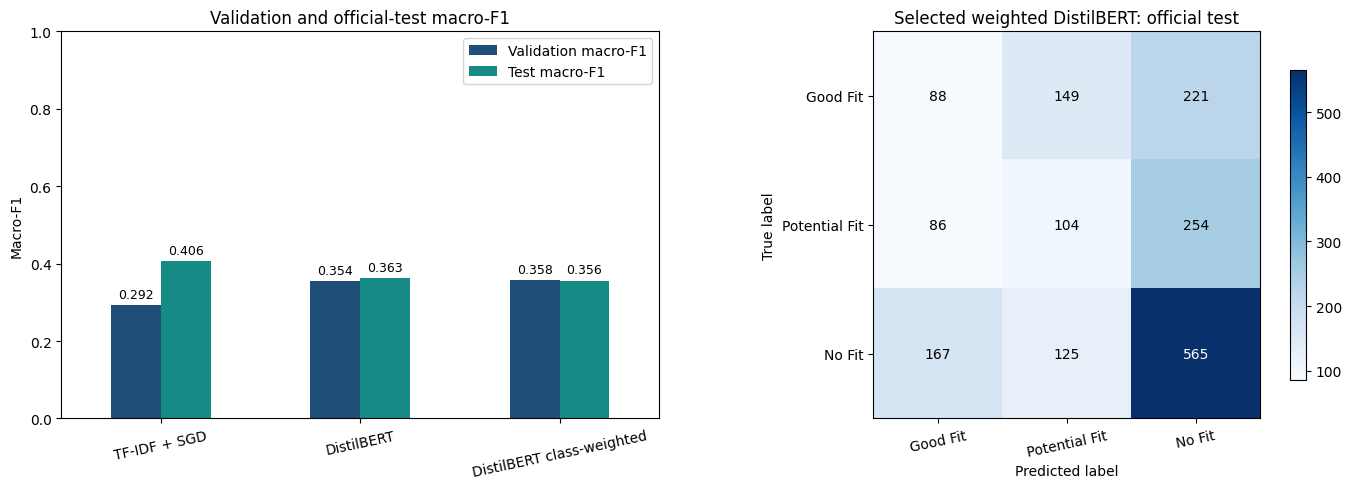

Figure saved to: /content/m4_final_evaluation/figures/final_evaluation.png


In [99]:
FIGURE_DIR = FINAL_EVALUATION_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plot_order = [
    "TF-IDF + SGD", "DistilBERT", "DistilBERT class-weighted"
]
score_plot = (
    validation_test_comparison.set_index("Model")
    .loc[plot_order, ["Validation macro-F1", "Test macro-F1"]]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

score_plot.plot(
    kind="bar", ax=axes[0],
    color=["#1F4E79", "#168A84"], rot=12
)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", padding=3, fontsize=9)

axes[0].set_title("Validation and official-test macro-F1")
axes[0].set_ylabel("Macro-F1")
axes[0].set_xlabel("")
axes[0].set_ylim(0, 1)

matrix = selected_test_confusion.to_numpy()
image = axes[1].imshow(matrix, cmap="Blues")

for row in range(3):
    for column in range(3):
        axes[1].text(
            column, row, str(matrix[row, column]),
            ha="center", va="center",
            color="white" if matrix[row, column] > matrix.max() / 2 else "black"
        )

axes[1].set_xticks(range(3), LABELS, rotation=12)
axes[1].set_yticks(range(3), LABELS)
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")
axes[1].set_title("Selected weighted DistilBERT: official test")
fig.colorbar(image, ax=axes[1], shrink=0.8)

fig.tight_layout()
figure_path = FIGURE_DIR / "final_evaluation.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Figure saved to:", figure_path)

## Write findings and verify saved evidence

Document protocols, limitations and results. Recompute scores and confusion matrices from saved predictions, check robustness totals and exclude source-text columns.


In [100]:
def markdown_table(frame):
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    separator = "| " + " | ".join(["---"] * len(frame.columns)) + " |"
    body = [
        "| " + " | ".join(map(str, row)) + " |"
        for row in frame.fillna("").itertuples(index=False, name=None)
    ]
    return "\n".join([header, separator, *body])


evaluation_report_path = FINAL_EVALUATION_DIR / "evaluation_report.md"

evaluation_report = f"""# Model Evaluation and Selection

## Evaluation setup

The task predicts Good Fit, Potential Fit, or No Fit for resume-job pairs.
Evaluation uses the saved M3 dataset revision and job-grouped splits:
5,081 training, 1,147 validation, and 1,759 official-test pairs.
Jobs and prepared pairs do not overlap across splits, but some resumes do.
Results therefore concern largely known candidates matched against unseen jobs.

Macro-F1 is the primary selection metric. TF-IDF uses full documents with its
original cleaning; transformers use their documented 512-token input policies.
This compares complete approaches rather than architecture alone.

## Validation and improvement iterations

{markdown_table(final_comparison_df.round(4))}

Section-aware preparation reduced macro-F1 relative to original DistilBERT.
Class weighting with original inputs produced a small 0.0042 validation gain.
These are single-seed experiments, with class-recall trade-offs.

## Frozen selection and official-test results

The weighted DistilBERT model was selected by validation macro-F1 before test
inference. Its weight hash, input policy, fixed comparators, and decision are
recorded in [model_selection.json](model_selection.json).
No threshold tuning or model reselection followed test evaluation.

{markdown_table(official_test_metrics.round(4))}

TF-IDF has the highest official-test macro-F1 among the fixed comparisons.
The weighted model's validation advantage over original DistilBERT does not
carry over to the test set. Transformer superiority is not established.

The selected model correctly identifies 88 of 458 Good Fit examples and
104 of 444 Potential Fit examples. It predicts No Fit for 221 Good Fit and
254 Potential Fit examples. These failures limit its usefulness for screening.
The recorded evaluation selection remains unchanged.
"""

evaluation_report_path.write_text(evaluation_report, encoding="utf-8")
print("Evaluation setup and results saved to:", evaluation_report_path)

Evaluation setup and results saved to: /content/m4_final_evaluation/evaluation_report.md


In [101]:
stress_table = robustness_results[
    robustness_results["Variant"].isin(
        ["block_order", "skills_removed", "long_prefix"]
    )
][[
    "Model", "Variant", "Changed inputs",
    "Change rate (%)", "Change rate on changed inputs (%)"
]]

evaluation_details = f"""
## Error review

Across validation, weighting fixes 59 original errors but introduces 68 regressions.
The qualitative review covers 30 deliberately balanced cases across 19 unique
job texts. Four Potential Fit regressions share one job, so observations are
correlated and category counts are not population prevalence estimates.

[Review findings](error_review_findings.md) describe specialist requirements,
label/evidence tensions, missing context, and text-quality issues.
This assistant-assisted review does not establish model causation or replace
recruiter adjudication. Dataset labels remain unchanged.

## Robustness testing

Tests use 300 validation pairs, with 100 per class. Whitespace and ASCII-case
changes yield identical tokenized inputs; their predictions are reused.
This verifies preparation behaviour rather than semantic model robustness.

{markdown_table(stress_table.round(2))}

Block-order tests reverse newline-separated blocks. Skills removal uses the
recorded heading rules, changing prepared text in 234 cases but tokenized input
in only 133. Long-prefix tests prepend 80 repetitions of review boilerplate
to the resume. These are diagnostic stress tests, not ordinary traffic estimates.

The weighted model changes more predictions in all three stress tests.
Prediction changes are sensitivity measurements, not automatically errors;
content removal can change the information needed to judge suitability.

## Inference measurements

{markdown_table(inference_results.round(3))}

Both saved models are measured separately on one T4 with FP16 autocast,
three warmup batches, and 30 timed repeats at batch sizes 1 and 16.
Inputs are already on the GPU. Timings exclude preparation, tokenization,
transfers, API handling, and output processing.
Memory is PyTorch allocation in 1024^3-byte units, not total device usage.

The models have the same architecture and similar measurements. One run does
not establish a speed advantage. CPU and end-to-end application performance
remain unmeasured.

## Limitations and further use

Findings depend on one seed, one dataset, shared resumes, substantial truncation,
and labels that need further review. The small validation gain is not evidence
of a reliable improvement or business impact. Suitable-candidate recall remains low.

Use the model only as a prototype with human review. Keep the frozen assessment
separate from future experiments; further tuning requires independent evaluation.

## Reproduction and evidence

Use the saved notebook, pinned dataset revision, M3 split archive, recorded
package versions, M3 transformer reports, and original DistilBERT model archive.
Keep trained models and the text-containing review CSV outside the reports archive.

The selection record predates test inference. Prediction CSVs, class reports,
confusion matrices, robustness records, and raw inference timings support
the reported calculations. See [the evaluation figure](figures/final_evaluation.png).
"""

full_evaluation_report = evaluation_report + evaluation_details
evaluation_report_path.write_text(
    full_evaluation_report, encoding="utf-8"
)

print("Full evaluation report saved to:", evaluation_report_path)

Full evaluation report saved to: /content/m4_final_evaluation/evaluation_report.md


In [102]:
robustness_manifest["transformation_settings"] = {
    "extra_whitespace": "Expand raw whitespace, then apply prepare_text",
    "case_change": "ASCII uppercase raw text, then apply prepare_text",
    "block_order": "Reverse prepared newline-separated blocks in both documents",
    "skills_removed": "Remove recognised resume skills blocks; preserve other lines",
    "long_prefix": {
        "resume_prefix": "Document provided for recruitment review. ",
        "repetitions": 80
    }
}
(FINAL_EVALUATION_DIR / "robustness_manifest.json").write_text(
    json.dumps(robustness_manifest, indent=2), encoding="utf-8"
)

inference_protocol["memory_unit"] = "1024^3 bytes"
inference_protocol["benchmark_order"] = [
    "DistilBERT class-weighted", "DistilBERT"
]
(FINAL_EVALUATION_DIR / "inference_protocol.json").write_text(
    json.dumps(inference_protocol, indent=2), encoding="utf-8"
)

evaluation_summary = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": split_manifest["dataset"],
    "dataset_revision": split_manifest["dataset_revision"],
    "split_manifest_sha256": weighted_run_config["split_manifest_sha256"],
    "seed": SEED,
    "label2id": LABEL2ID,
    "package_versions": weighted_run_config["package_versions"],
    "selected_model": frozen_selection["selected_model"],
    "selected_weights_sha256": frozen_selection["selected_weights_sha256"],
    "selection_changed_after_test": False,
    "official_test_evaluated": True,
    "official_test_rows": len(test_df),
    "selected_test_result": official_test_metrics.set_index("Model").loc[
        frozen_selection["selected_model"]
    ].to_dict(),
    "highest_test_macro_f1_model": official_test_metrics.loc[
        official_test_metrics["Test macro-F1"].idxmax(), "Model"
    ],
    "reviewed_validation_cases": len(error_review_sample),
    "robustness_pairs_per_variant": len(robustness_sample_df),
    "robustness_variants": len(ROBUSTNESS_PROTOCOL),
    "inference_repeats_per_setting": INFERENCE_REPEATS
}

(FINAL_EVALUATION_DIR / "evaluation_summary.json").write_text(
    json.dumps(evaluation_summary, indent=2), encoding="utf-8"
)

print("Evaluation summary and detailed protocols saved.")
print("Selected model:", evaluation_summary["selected_model"])
print("Highest test macro-F1:", evaluation_summary["highest_test_macro_f1_model"])
print("Selection changed after test:", evaluation_summary["selection_changed_after_test"])

Evaluation summary and detailed protocols saved.
Selected model: DistilBERT class-weighted
Highest test macro-F1: TF-IDF + SGD
Selection changed after test: False


In [103]:
saved_test_predictions = pd.read_csv(
    FINAL_EVALUATION_DIR / "official_test_predictions.csv"
)
saved_test_metrics = pd.read_csv(
    FINAL_EVALUATION_DIR / "official_test_metrics.csv"
).set_index("Model")

np.testing.assert_array_equal(
    saved_test_predictions["source_row_id"],
    split_manifest["source_row_ids"]["Official test"]
)
np.testing.assert_array_equal(
    saved_test_predictions["true_label"],
    test_df["label"].to_numpy()
)

for model_name, folder_name in test_report_folders.items():
    true_labels = saved_test_predictions["true_label"]
    predictions = saved_test_predictions[model_name]

    np.testing.assert_allclose(
        f1_score(
            true_labels, predictions,
            labels=LABELS, average="macro", zero_division=0
        ),
        saved_test_metrics.loc[model_name, "Test macro-F1"],
        rtol=1e-12
    )
    np.testing.assert_allclose(
        accuracy_score(true_labels, predictions),
        saved_test_metrics.loc[model_name, "Test accuracy"],
        rtol=1e-12
    )

    saved_matrix = pd.read_csv(
        FINAL_EVALUATION_DIR / "test_reports"
        / folder_name / "confusion_matrix.csv",
        index_col=0
    )
    np.testing.assert_array_equal(
        confusion_matrix(true_labels, predictions, labels=LABELS),
        saved_matrix.to_numpy()
    )

assert json.loads(SELECTION_PATH.read_text()) == frozen_selection
assert saved_test_metrics.query("Role == 'Selected'").index.tolist() == [
    frozen_selection["selected_model"]
]

final_checks = {
    "test_predictions_and_metrics_match": True,
    "test_confusion_matrices_match": True,
    "frozen_selection_unchanged": True
}

print("All three saved test scores and confusion matrices reproduce exactly.")
print("The frozen selection record remains unchanged.")

All three saved test scores and confusion matrices reproduce exactly.
The frozen selection record remains unchanged.


In [104]:
saved_robustness = pd.read_csv(
    FINAL_EVALUATION_DIR / "robustness_predictions.csv"
)

for row in robustness_results.to_dict("records"):
    group = saved_robustness[
        (saved_robustness["Model"] == row["Model"])
        & (saved_robustness["Variant"] == row["Variant"])
    ]
    flips = group["prediction"] != group["baseline_prediction"]

    assert len(group) == 300
    assert group["source_row_id"].is_unique
    assert int(flips.sum()) == row["Prediction changes"]
    assert int(group["input_changed"].sum()) == row["Changed inputs"]
    assert int(flips[~group["input_changed"]].sum()) == (
        row["Unchanged-input flips"]
    )
    np.testing.assert_allclose(
        100 * flips.mean(), row["Change rate (%)"], atol=1e-12
    )

saved_timings = pd.read_csv(
    FINAL_EVALUATION_DIR / "inference_timings.csv"
)

for row in inference_results.to_dict("records"):
    times = saved_timings[
        (saved_timings["Model"] == row["Model"])
        & (saved_timings["Batch size"] == row["Batch size"])
    ]["Seconds"].to_numpy()

    assert len(times) == INFERENCE_REPEATS
    assert (times > 0).all()
    expected = {
        "Median batch ms": np.median(times) * 1000,
        "P95 batch ms": np.percentile(times, 95) * 1000,
        "Examples per second": row["Batch size"] / times.mean()
    }
    for column, value in expected.items():
        np.testing.assert_allclose(value, row[column], rtol=1e-10)

for path in FINAL_EVALUATION_DIR.rglob("*.csv"):
    columns = set(pd.read_csv(path, nrows=0).columns)
    assert not {
        "resume_text", "resume_model_text", "job_description_text",
        "job_model_text", "visible_model_input"
    }.intersection(columns), path.name

assert error_review_sample["review_category"].str.strip().ne("").all()
assert error_review_sample["evidence_notes"].str.strip().ne("").all()

final_checks.update({
    "robustness_records_match": True,
    "inference_calculations_match": True,
    "review_annotations_complete": True,
    "document_text_columns_excluded": True,
    "passed": True
})
(FINAL_EVALUATION_DIR / "verification.json").write_text(
    json.dumps(final_checks, indent=2), encoding="utf-8"
)

print("Robustness totals and inference calculations match.")
print("Review annotations are filled; source-text columns are excluded.")
print("Final verification passed.")

Robustness totals and inference calculations match.
Review annotations are filled; source-text columns are excluded.
Final verification passed.


In [105]:
report_files = sorted(
    path for path in FINAL_EVALUATION_DIR.rglob("*")
    if path.is_file() and path.name != "artifact_manifest.json"
)

artifact_entries = []

for path in report_files:
    assert path.suffix not in {".safetensors", ".joblib", ".bin", ".zip"}
    assert path.name != "error_review_with_text.csv"

    with path.open("rb") as file:
        checksum = hashlib.file_digest(file, "sha256").hexdigest()

    artifact_entries.append({
        "path": str(path.relative_to(FINAL_EVALUATION_DIR)),
        "bytes": path.stat().st_size,
        "sha256": checksum
    })

(FINAL_EVALUATION_DIR / "artifact_manifest.json").write_text(
    json.dumps({"files": artifact_entries}, indent=2),
    encoding="utf-8"
)

final_reports_archive = Path("/content/m4_final_evaluation_reports.zip")

with ZipFile(final_reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(FINAL_EVALUATION_DIR.rglob("*")):
        if path.is_file():
            archive.write(
                path, str(path.relative_to(FINAL_EVALUATION_DIR))
            )

with ZipFile(final_reports_archive) as archive:
    assert archive.testzip() is None
    for entry in artifact_entries:
        assert hashlib.sha256(
            archive.read(entry["path"])
        ).hexdigest() == entry["sha256"]

    print(
        f"{final_reports_archive.name}: "
        f"{len(archive.namelist())} files, "
        f"{final_reports_archive.stat().st_size / 1024**2:.2f} MB"
    )

files.download(str(final_reports_archive))

m4_final_evaluation_reports.zip: 27 files, 0.24 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>